In [1]:
message = 'Han, Mitakuyapi!'
print(message)

Han, Mitakuyapi!


In [2]:

# ============================================================
# SA 20 — CELL 1
# ATE_MACOKE: FIND EXISTING GIS AND NDVI RESULTS
# Read-only inventory — no recalculation or overwriting
# ============================================================

from pathlib import Path
import pandas as pd

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

if not project.is_dir():
    raise FileNotFoundError(
        f"Project folder not found:\n{project}"
    )

extensions = {
    ".tif", ".tiff", ".csv", ".nc",
    ".npy", ".npz", ".gpkg", ".shp"
}

keywords = [
    "ndvi", "ndmi", "vegetation", "trajectory",
    "landsat", "makoce", "wanzi",
    "classification", "sensitivity",
    "2019", "2022", "2023"
]

records = []

for path in project.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    relative = str(path.relative_to(project))
    name = path.name.lower()

    if any(word in name for word in keywords):

        records.append({
            "Filename": path.name,
            "Format": path.suffix.lower(),
            "Size_MB": round(
                path.stat().st_size / 1048576, 2
            ),
            "Relative_Path": relative,
            "Full_Path": str(path)
        })

gis_inventory = pd.DataFrame(records)

print("ATE_MACOKE — EXISTING DATA INVENTORY")
print("=" * 55)
print("Matching files:", len(gis_inventory))

if not gis_inventory.empty:

    gis_inventory = gis_inventory.sort_values(
        ["Format", "Filename"]
    ).reset_index(drop=True)

    display(gis_inventory[
        [
            "Filename",
            "Format",
            "Size_MB",
            "Relative_Path"
        ]
    ])

    inventory_dir = (
        project / "results" / "SA20_satellite_maps"
    )
    inventory_dir.mkdir(
        parents=True, exist_ok=True
    )

    inventory_path = (
        inventory_dir / "Ate_Macoke_Data_Inventory.csv"
    )

    gis_inventory.to_csv(
        inventory_path,
        index=False
    )

    print("\nInventory saved to:")
    print(inventory_path)

else:
    print(
        "No matching saved data files found. "
        "We will inspect Notebook 09's saved outputs next."
    )

print("\nOriginal Notebook 09 unchanged.")


ATE_MACOKE — EXISTING DATA INVENTORY
Matching files: 92


,Filename,Format,Size_MB,Relative_Path
0,01_historical_modis_ndvi_completeness_audit.csv,.csv,0.02,data/cache/dissertation_validation/01_historic...
1,01_historical_modis_qa_regional_2003_2023.csv,.csv,0.00,data/cache/dissertation_validation/01_historic...
2,01_historical_modis_qa_sensitivity_by_date.csv,.csv,0.00,data/cache/dissertation_validation/01_historic...
3,01_historical_modis_qa_summary_2003_2023.csv,.csv,0.00,data/cache/dissertation_validation/01_historic...
4,01_historical_ndvi_reproducibility.csv,.csv,0.01,data/cache/dissertation_validation/01_historic...
...,...,...,...,...
87,pine_ridge_ndvi_monthly.nc,.nc,0.02,data/cache/pine_ridge_ndvi_monthly.nc
88,spatial_grid_0.5deg_2000_2023.nc,.nc,0.01,data/cache/spatial_grid_0.5deg_2000_2023.nc
89,ate_parcel_wanzi.shp,.shp,0.00,data/ate_parcel_wanzi.shp
90,ate_makoce_vegetation_trajectories_2019_2023.tif,.tif,0.00,outputs/sa16_16_ate_makoce_final/v01/ate_makoc...



Inventory saved to:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Data_Inventory.csv

Original Notebook 09 unchanged.


In [7]:

# ============================================================
# SA 20 — CELL 2
# IDENTIFY EXISTING NDVI DATA FOR ATE_MACOKE
# ============================================================

import pandas as pd
from pathlib import Path

print("ATE_MACOKE — NDVI DATA DISCOVERY")
print("=" * 60)

# Use the inventory created in Cell 1
if "gis_inventory" not in globals():
    raise RuntimeError("Please run Cell 1 first.")

# Find potential NDVI raster datasets
raster_candidates = gis_inventory[
    gis_inventory["Format"].isin(
        [".tif", ".tiff", ".nc", ".npy", ".npz"]
    )
].copy()

print("\n1. AVAILABLE RASTER DATASETS")
display(
    raster_candidates[
        ["Filename", "Format", "Size_MB", "Relative_Path"]
    ].to_string(index=False)
)

# Find CSV files related to NDVI and vegetation change
csv_candidates = gis_inventory[
    (gis_inventory["Format"] == ".csv")
    & gis_inventory["Filename"].str.contains(
        "ndvi|vegetation|landsat|change",
        case=False,
        regex=True
    )
].copy()

print("\n2. AVAILABLE NDVI / VEGETATION CSV FILES")

if not csv_candidates.empty:
    display(
        csv_candidates[
            ["Filename", "Size_MB", "Relative_Path"]
        ]
    )
else:
    print("No matching CSV files found.")

# Check the known trajectory raster
trajectory_matches = gis_inventory[
    gis_inventory["Filename"].str.contains(
        "vegetation_trajectories_2019_2023",
        case=False,
        regex=False
    )
]

print("\n3. EXISTING VEGETATION TRAJECTORY MAP")

if not trajectory_matches.empty:
    display(
        trajectory_matches[
            ["Filename", "Relative_Path"]
        ]
    )

print("\nDiscovery complete.")
print("No original files were modified.")


ATE_MACOKE — NDVI DATA DISCOVERY

1. AVAILABLE RASTER DATASETS


'                                                               Filename Format  Size_MB                                                                         Relative_Path\n                     environmental_data_cube_oglala_lakota_2000_2023.nc    .nc     0.00                          Notebooks/environmental_data_cube_oglala_lakota_2000_2023.nc\n    environmental_data_cube_oglala_lakota_2000_2023_validated_evi_v2.nc    .nc     0.02        data/cache/environmental_data_cube_oglala_lakota_2000_2023_validated_evi_v2.nc\n            environmental_data_cube_oglala_lakota_2000_2023_with_evi.nc    .nc     0.01                data/cache/environmental_data_cube_oglala_lakota_2000_2023_with_evi.nc\n                     environmental_data_cube_oglala_lakota_2015_2023.nc    .nc     0.01                         data/cache/environmental_data_cube_oglala_lakota_2015_2023.nc\n   environmental_data_cube_oglala_lakota_2015_2023_before_evi_update.nc    .nc     0.01       data/cache/environmental_data_


2. AVAILABLE NDVI / VEGETATION CSV FILES


,Filename,Size_MB,Relative_Path
0,01_historical_modis_ndvi_completeness_audit.csv,0.02,data/cache/dissertation_validation/01_historic...
4,01_historical_ndvi_reproducibility.csv,0.01,data/cache/dissertation_validation/01_historic...
6,01_modis_ndvi_by_joint_qa_profile_sep_2023.csv,0.00,data/cache/dissertation_validation/01_modis_nd...
7,01_modis_ndvi_by_reliability_class_sep_2023.csv,0.00,data/cache/dissertation_validation/01_modis_nd...
14,02_historical_spatial_ndvi_summary.csv,0.00,data/cache/dissertation_validation/02_historic...
23,04_modis_qa_ndvi_sensitivity.csv,0.00,data/cache/dissertation_validation/04_modis_qa...
25,06_ndvi_aggregation_comparison.csv,0.00,data/cache/dissertation_validation/06_ndvi_agg...
26,06_ndvi_annual_source_consistency.csv,0.00,data/cache/dissertation_validation/06_ndvi_ann...
27,06_ndvi_systematic_difference_summary.csv,0.00,data/cache/dissertation_validation/06_ndvi_sys...
29,08_inside_reservation_annual_ndvi.csv,0.00,data/cache/dissertation_validation/08_inside_r...



3. EXISTING VEGETATION TRAJECTORY MAP


,Filename,Relative_Path
90,ate_makoce_vegetation_trajectories_2019_2023.tif,outputs/sa16_16_ate_makoce_final/v01/ate_makoc...



Discovery complete.
No original files were modified.


In [8]:

# ============================================================
# SA 20 — CELL 3 (CORRECTED)
# ATE_MACOKE: PRESERVE AND EXPORT EXISTING GIS RESULTS
#
# Exports:
#   1. Original vegetation trajectory GeoTIFF copy
#   2. Pixel-level CSV with geographic coordinates
#   3. Vegetation trajectory class summary CSV
#
# Does NOT recalculate NDVI or modify Notebook 09.
# ============================================================

from pathlib import Path
from shutil import copy2

import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import xy
from IPython.display import display

# ------------------------------------------------------------
# 1. PROJECT AND OUTPUT PATHS
# ------------------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

source_raster = (
    project
    / "outputs/sa16_16_ate_makoce_final/v01"
    / "ate_makoce_vegetation_trajectories_2019_2023.tif"
)

output_dir = (
    project / "results/SA20_satellite_maps"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

if not source_raster.exists():
    raise FileNotFoundError(
        f"Original trajectory raster not found:\n"
        f"{source_raster}"
    )

# ------------------------------------------------------------
# 2. OPEN ORIGINAL GEOTIFF
# ------------------------------------------------------------

with rasterio.open(source_raster) as src:

    if src.crs is None:
        raise ValueError(
            "Source raster has no coordinate reference system."
        )

    if src.count != 1:
        raise ValueError(
            "Expected a single-band classification raster."
        )

    data = src.read(1, masked=True)

    raster_crs = src.crs
    raster_transform = src.transform
    raster_width = src.width
    raster_height = src.height
    raster_resolution = src.res
    raster_nodata = src.nodata

    print("ATE_MACOKE — ORIGINAL GIS RASTER")
    print("=" * 55)

    print("File:", source_raster.name)
    print("CRS:", raster_crs)
    print("Resolution:", raster_resolution)
    print(
        "Dimensions:",
        raster_width,
        "x",
        raster_height
    )
    print("Data type:", data.dtype)
    print("NoData:", raster_nodata)

    # --------------------------------------------------------
    # 3. IDENTIFY VALID PIXELS
    # --------------------------------------------------------

    # CORRECTED:
    # Do not use data.filled(np.nan) on integer rasters.
    # Keep original uint8 classification values intact.

    valid_mask = ~np.ma.getmaskarray(data)

    valid_mask &= np.isfinite(data.data)

    rows, cols = np.where(valid_mask)

    if len(rows) == 0:
        raise ValueError(
            "No valid pixels found in the trajectory raster."
        )

    values = np.asarray(
        data.data[rows, cols]
    )

    print("Valid pixels:", len(values))
    print(
        "Original class values:",
        np.unique(values).tolist()
    )

    # --------------------------------------------------------
    # 4. GET GEOGRAPHIC COORDINATES
    # --------------------------------------------------------

    x_coords, y_coords = xy(
        raster_transform,
        rows,
        cols,
        offset="center"
    )

    # --------------------------------------------------------
    # 5. CREATE PIXEL-LEVEL CSV TABLE
    # --------------------------------------------------------

    pixel_table = pd.DataFrame({
        "row": rows,
        "column": cols,
        "x": np.asarray(x_coords),
        "y": np.asarray(y_coords),
        "trajectory_class": values
    })

    pixel_table["crs"] = str(raster_crs)

    # --------------------------------------------------------
    # 6. CREATE CLASS SUMMARY
    # --------------------------------------------------------

    class_summary = (
        pixel_table
        .groupby("trajectory_class")
        .size()
        .reset_index(name="pixel_count")
    )

    class_summary["percent"] = (
        100
        * class_summary["pixel_count"]
        / len(pixel_table)
    ).round(2)

    # Calculate pixel area only for projected CRS
    # with meter-based coordinate units.

    if (
        raster_crs.is_projected
        and raster_crs.linear_units_factor is not None
    ):
        unit_to_meters = raster_crs.linear_units_factor[1]

        pixel_area_m2 = (
            abs(
                raster_transform.a * raster_transform.e
                - raster_transform.b * raster_transform.d
            )
            * unit_to_meters ** 2
        )

    else:
        pixel_area_m2 = np.nan

    class_summary["area_ha"] = (
        class_summary["pixel_count"]
        * pixel_area_m2
        / 10000
    ).round(3)

# ------------------------------------------------------------
# 7. DEFINE OUTPUT FILES
# ------------------------------------------------------------

tif_output = (
    output_dir
    / "Ate_Macoke_Vegetation_Trajectories_2019_2023.tif"
)

csv_output = (
    output_dir
    / "Ate_Macoke_Vegetation_Trajectories_Pixels.csv"
)

summary_output = (
    output_dir
    / "Ate_Macoke_Vegetation_Trajectories_Summary.csv"
)

# ------------------------------------------------------------
# 8. EXPORT WITHOUT OVERWRITING EXISTING FILES
# ------------------------------------------------------------

if not tif_output.exists():

    copy2(source_raster, tif_output)

    print("\nGeoTIFF saved:")
    print(tif_output)

else:
    print("\nGeoTIFF already exists; not overwritten.")

if not csv_output.exists():

    pixel_table.to_csv(
        csv_output,
        index=False
    )

    print("\nPixel CSV saved:")
    print(csv_output)

else:
    print("\nPixel CSV already exists; not overwritten.")

if not summary_output.exists():

    class_summary.to_csv(
        summary_output,
        index=False
    )

    print("\nClass summary CSV saved:")
    print(summary_output)

else:
    print("\nClass summary CSV already exists; not overwritten.")

# ------------------------------------------------------------
# 9. DISPLAY CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\nATE_MACOKE — VEGETATION TRAJECTORY CLASSES")
print("=" * 55)

display(class_summary)

print("\nSA 20 CELL 3 COMPLETE")
print("Original Notebook 09 unchanged.")
print("Original GeoTIFF unchanged.")
print("GIS-ready copies created where not already present.")


ATE_MACOKE — ORIGINAL GIS RASTER
File: ate_makoce_vegetation_trajectories_2019_2023.tif
CRS: EPSG:32613
Resolution: (30.0, 30.0)
Dimensions: 58 x 56
Data type: uint8
NoData: 255.0
Valid pixels: 2878
Original class values: [0, 1, 2, 3, 4, 5]

GeoTIFF saved:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Vegetation_Trajectories_2019_2023.tif

Pixel CSV saved:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Vegetation_Trajectories_Pixels.csv

Class summary CSV saved:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Vegetation_Trajectories_Summary.csv

ATE_MACOKE — VEGETATION TRAJECTORY CLASSES


,trajectory_class,pixel_count,percent,area_ha
0,0,85,2.95,7.65
1,1,1190,41.35,107.10
2,2,6,0.21,0.54
3,3,290,10.08,26.10
4,4,493,17.13,44.37
5,5,814,28.28,73.26



SA 20 CELL 3 COMPLETE
Original Notebook 09 unchanged.
Original GeoTIFF unchanged.
GIS-ready copies created where not already present.


In [9]:

# ============================================================
# SA 20 — CELL 4
# ATE_MACOKE: PREVIEW ORIGINAL VEGETATION TRAJECTORY MAP
# No recalculation, no changes to source data
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import rasterio

from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

raster_path = (
    project
    / "results/SA20_satellite_maps"
    / "Ate_Macoke_Vegetation_Trajectories_2019_2023.tif"
)

# Temporary display colors.
# We will assign scientifically appropriate class colors
# after verifying Notebook 09's class definitions.

class_colors = [
    "#8C8C8C",  # Class 0
    "#B85C50",  # Class 1
    "#E8A35D",  # Class 2
    "#E5D6A1",  # Class 3
    "#80A88A",  # Class 4
    "#287B59"   # Class 5
]

with rasterio.open(raster_path) as src:

    raster = src.read(1, masked=True)

    bounds = src.bounds

    extent = [
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ]

    print("Coordinate system:", src.crs)
    print("Original classes:", np.unique(
        raster.compressed()
    ).tolist())

cmap = ListedColormap(class_colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    np.arange(-0.5, 6.5, 1),
    cmap.N
)

fig, ax = plt.subplots(figsize=(9, 9))

ax.imshow(
    raster,
    cmap=cmap,
    norm=norm,
    extent=extent,
    origin="upper",
    interpolation="nearest"
)

legend_items = [
    Patch(
        facecolor=class_colors[i],
        edgecolor="black",
        linewidth=0.4,
        label=f"Original Class {i}"
    )
    for i in range(6)
]

ax.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    title="Trajectory classes",
    frameon=False
)

ax.set_title(
    "Ate_Macoke\n"
    "Vegetation Trajectories (2019–2023)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_aspect("equal")
ax.ticklabel_format(style="plain", useOffset=False)

plt.tight_layout()
plt.show()

print(
    "\nPreview complete. "
    "Original classification values unchanged."
)


Coordinate system: EPSG:32613
Original classes: [0, 1, 2, 3, 4, 5]


<Figure size 900x900 with 1 Axes>


Preview complete. Original classification values unchanged.


In [28]:

# ============================================================
# SA 20 — CELL 5
# RECOVER ORIGINAL VEGETATION CLASS DEFINITIONS
# FROM NOTEBOOK 09
#
# Read-only: does not execute or modify Notebook 09
# ============================================================

from pathlib import Path
import json
import re

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

notebook09 = (
    project
    / "Notebooks/09_dissertation_data_cube_validation.ipynb"
)

if not notebook09.exists():
    raise FileNotFoundError(
        f"Notebook 09 not found:\n{notebook09}"
    )

with open(notebook09, "r", encoding="utf-8") as f:
    notebook = json.load(f)

search_terms = [
    r"vegetation.trajectory",
    r"trajectory.class",
    r"class.labels",
    r"class.names",
    r"class.colors",
    r"classification.summary",
    r"sa\s*16\.16",
    r"threshold.sensitivity",
]

pattern = re.compile(
    "|".join(search_terms),
    flags=re.IGNORECASE
)

matches = []

for cell_index, cell in enumerate(
    notebook.get("cells", [])
):
    source = "".join(
        cell.get("source", [])
    )

    if pattern.search(source):
        matches.append((cell_index, source))

print("ATE_MACOKE — NOTEBOOK 09 CLASS DEFINITIONS")
print("=" * 65)

print("Matching cells:", len(matches))

for cell_index, source in matches:

    print("\n" + "=" * 65)
    print(f"NOTEBOOK 09 — CELL {cell_index}")
    print("=" * 65)

    lines = source.splitlines()

    matching_line_numbers = [
        i for i, line in enumerate(lines)
        if pattern.search(line)
    ]

    selected_lines = set()

    for i in matching_line_numbers:
        selected_lines.update(
            range(
                max(0, i - 5),
                min(len(lines), i + 12)
            )
        )

    for i in sorted(selected_lines):
        print(f"{i + 1:03d}: {lines[i]}")

print("\nSearch complete.")
print("Notebook 09 unchanged.")


ATE_MACOKE — NOTEBOOK 09 CLASS DEFINITIONS
Matching cells: 17

NOTEBOOK 09 — CELL 300
001: 
002: # ============================================================
003: # SA 16.9 — WANZI VEGETATION TRAJECTORY MAP
004: # Environmental Data Cube for Oglala Lakota
005: # 2019 → 2022 → 2023
006: # READ ONLY — no files modified
007: # ============================================================
008: 
009: import numpy as np
010: import pandas as pd
011: import matplotlib.pyplot as plt
012: from matplotlib.colors import ListedColormap, BoundaryNorm
013: from matplotlib.patches import Patch
014: 
147:         )
148:     })
149: 
150: summary = pd.DataFrame(records)
151: 
152: print("\nVEGETATION TRAJECTORY SUMMARY")
153: display(summary.round(2))
154: 
155: print("\nThree-year valid coverage:",
156:       round(100 * n_valid / parcel_mask.sum(), 2), "%")
157: 
158: # ------------------------------------------------------------
159: # 5. Create map
160: # ------------------------------------------

Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Verified_Vegetation_Trajectories.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Verified_Vegetation_Trajectories.pdf


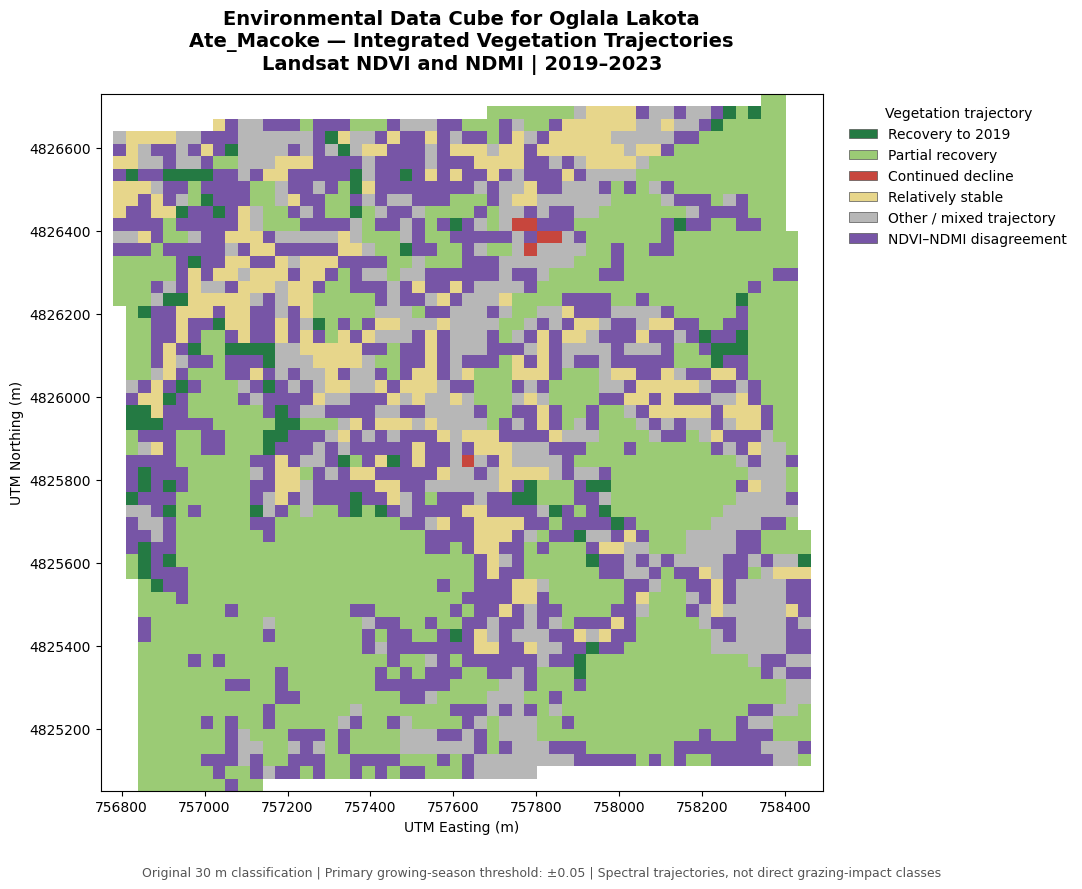


Verified vegetation trajectory map complete.
Original Notebook 09 and GIS data unchanged.


In [11]:

# ============================================================
# SA 20 — CELL 6
# ATE_MACOKE — VERIFIED VEGETATION TRAJECTORY MAP
# Uses existing Notebook 09 classification GeoTIFF
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

output_dir = (
    project / "results/SA20_satellite_maps"
)

raster_path = (
    output_dir
    / "Ate_Macoke_Vegetation_Trajectories_2019_2023.tif"
)

# Original class definitions from Notebook 09
class_labels = {
    0: "Recovery to 2019",
    1: "Partial recovery",
    2: "Continued decline",
    3: "Relatively stable",
    4: "Other / mixed trajectory",
    5: "NDVI–NDMI disagreement"
}

# Colors chosen to distinguish trajectory categories.
# These are presentation colors, not new classifications.
class_colors = [
    "#247A43",  # Recovery to 2019
    "#9BCB75",  # Partial recovery
    "#C7463D",  # Continued decline
    "#E7D68B",  # Relatively stable
    "#B7B7B7",  # Other / mixed
    "#7755A6"   # NDVI–NDMI disagreement
]

with rasterio.open(raster_path) as src:
    data = src.read(1, masked=True)
    bounds = src.bounds

    extent = [
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ]

    crs = src.crs

cmap = ListedColormap(class_colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    np.arange(-0.5, 6.5, 1),
    cmap.N
)

fig, ax = plt.subplots(figsize=(11, 9))

ax.imshow(
    data,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

legend_handles = [
    Patch(
        facecolor=class_colors[i],
        edgecolor="#555555",
        linewidth=0.5,
        label=class_labels[i]
    )
    for i in range(6)
]

ax.legend(
    handles=legend_handles,
    title="Vegetation trajectory",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=10
)

ax.set_title(
    "Environmental Data Cube for Oglala Lakota\n"
    "Ate_Macoke — Integrated Vegetation Trajectories\n"
    "Landsat NDVI and NDMI | 2019–2023",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_aspect("equal")
ax.ticklabel_format(style="plain", useOffset=False)

fig.text(
    0.5,
    0.02,
    "Original 30 m classification | "
    "Primary growing-season threshold: ±0.05 | "
    "Spectral trajectories, not direct grazing-impact classes",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

for extension in ["png", "pdf"]:
    path = output_dir / (
        f"Ate_Macoke_Verified_Vegetation_Trajectories."
        f"{extension}"
    )

    # Avoid overwriting an existing figure
    if path.exists():
        version = 2
        while True:
            candidate = output_dir / (
                "Ate_Macoke_Verified_Vegetation_Trajectories"
                f"_v{version}.{extension}"
            )
            if not candidate.exists():
                path = candidate
                break
            version += 1

    fig.savefig(
        path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", path)

plt.show()

print("\nVerified vegetation trajectory map complete.")
print("Original Notebook 09 and GIS data unchanged.")


GeoTIFF saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Three_Class_Vegetation_Trajectories.tif
Pixel CSV saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Three_Class_Pixels.csv
Summary CSV saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Three_Class_Summary.csv

THREE-CLASS SUMMARY


,three_class,class_label,pixel_count,percent,area_ha
0,1,Recovery,1275,44.30,114.75
1,2,Continued decline,6,0.21,0.54
2,3,Stable / mixed / disagreement,1597,55.49,143.73


Map saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Three_Class_Vegetation_Map.png
Map saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Three_Class_Vegetation_Map.pdf


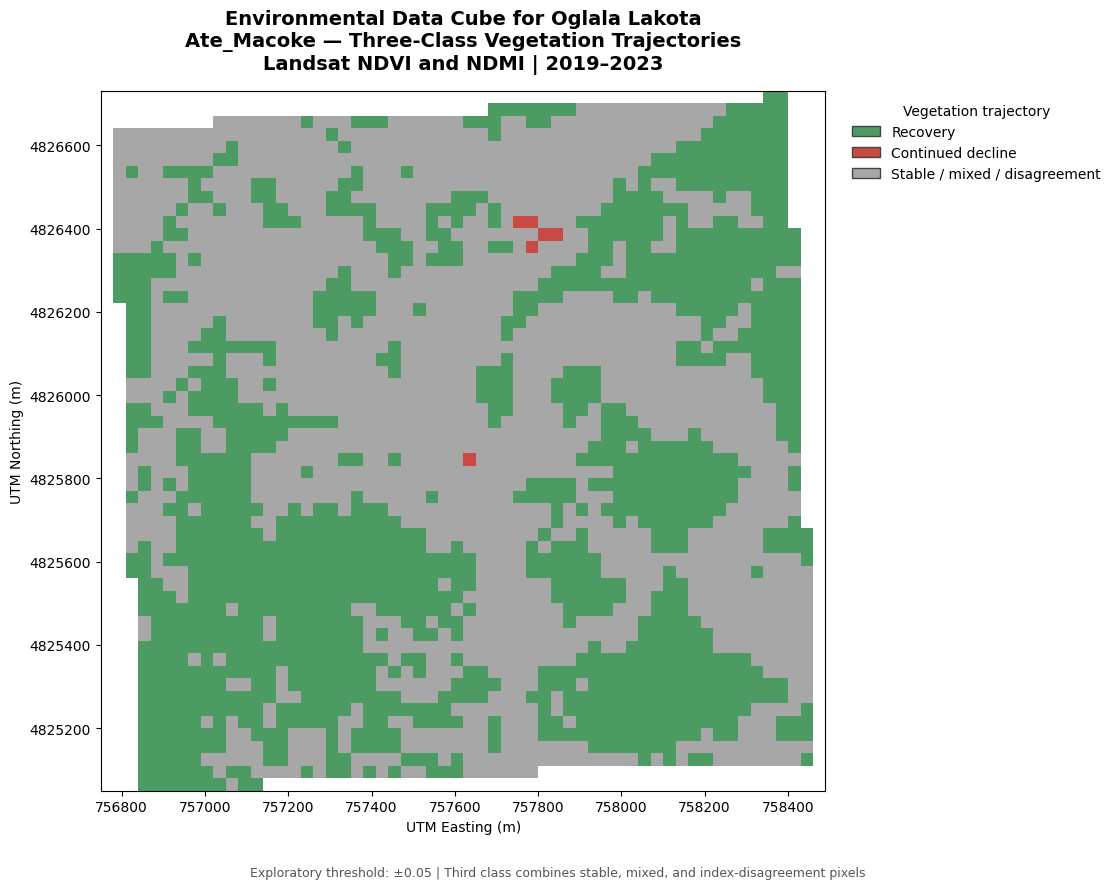


SA 20 — THREE-CLASS MAP COMPLETE
Original Notebook 09 and six-class raster unchanged.


In [12]:

# ============================================================
# SA 20 — CELL 6: THREE-CLASS VEGETATION TRAJECTORY MAP
# ATE_MACOKE — Environmental Data Cube for Oglala Lakota
#
# Uses EXISTING Notebook 09 results.
# Does NOT recalculate NDVI or modify original data.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from rasterio.transform import xy

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

output_dir = project / "results/SA20_satellite_maps"
output_dir.mkdir(parents=True, exist_ok=True)

source_path = (
    output_dir
    / "Ate_Macoke_Vegetation_Trajectories_2019_2023.tif"
)

# ------------------------------------------------------------
# 1. DEFINE THREE CLASSES
# ------------------------------------------------------------

class_labels = {
    1: "Recovery",
    2: "Continued decline",
    3: "Stable / mixed / disagreement"
}

class_colors = [
    "#4B9B62",  # Recovery — green
    "#C84A42",  # Continued decline — red
    "#A7A7A7"   # Stable / mixed / disagreement — gray
]

# Original classes -> simplified classes
reclass_map = {
    0: 1,
    1: 1,
    2: 2,
    3: 3,
    4: 3,
    5: 3
}

# ------------------------------------------------------------
# 2. READ EXISTING SIX-CLASS RASTER
# ------------------------------------------------------------

with rasterio.open(source_path) as src:

    original = src.read(1, masked=True)
    profile = src.profile.copy()
    bounds = src.bounds
    transform = src.transform
    crs = src.crs

    valid = ~np.ma.getmaskarray(original)

    found = set(np.unique(original.data[valid]).tolist())
    expected = set(reclass_map)

    if not found.issubset(expected):
        raise ValueError(
            f"Unexpected original classes: {found - expected}"
        )

    # Preserve NoData as 255
    reclassified = np.full(
        original.shape,
        255,
        dtype=np.uint8
    )

    for old_class, new_class in reclass_map.items():
        reclassified[
            valid & (original.data == old_class)
        ] = new_class

    profile.update(
        dtype="uint8",
        count=1,
        nodata=255
    )

# ------------------------------------------------------------
# 3. EXPORT NEW THREE-CLASS GEOTIFF
# ------------------------------------------------------------

tif_path = (
    output_dir
    / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

if not tif_path.exists():
    with rasterio.open(tif_path, "w", **profile) as dst:
        dst.write(reclassified, 1)
        dst.write_colormap(
            1,
            {
                1: (75, 155, 98, 255),
                2: (200, 74, 66, 255),
                3: (167, 167, 167, 255),
                255: (0, 0, 0, 0)
            }
        )
    print("GeoTIFF saved:", tif_path)
else:
    print("GeoTIFF exists; not overwritten:", tif_path)

# ------------------------------------------------------------
# 4. EXPORT PIXEL CSV AND CLASS SUMMARY
# ------------------------------------------------------------

rows, cols = np.where(reclassified != 255)

x_coords, y_coords = xy(
    transform,
    rows,
    cols,
    offset="center"
)

pixel_df = pd.DataFrame({
    "row": rows,
    "column": cols,
    "x": x_coords,
    "y": y_coords,
    "original_class": original.data[rows, cols],
    "three_class": reclassified[rows, cols]
})

pixel_df["class_label"] = (
    pixel_df["three_class"].map(class_labels)
)

pixel_df["crs"] = str(crs)

summary = (
    pixel_df.groupby(
        ["three_class", "class_label"]
    )
    .size()
    .reset_index(name="pixel_count")
)

summary["percent"] = (
    100 * summary["pixel_count"] / len(pixel_df)
).round(2)

unit_to_meters = (
    crs.linear_units_factor[1]
    if crs.is_projected
    else np.nan
)

pixel_area_m2 = (
    abs(
        transform.a * transform.e
        - transform.b * transform.d
    ) * unit_to_meters**2
)

summary["area_ha"] = (
    summary["pixel_count"] * pixel_area_m2 / 10000
).round(2)

csv_path = (
    output_dir
    / "Ate_Macoke_Three_Class_Pixels.csv"
)

summary_path = (
    output_dir
    / "Ate_Macoke_Three_Class_Summary.csv"
)

if not csv_path.exists():
    pixel_df.to_csv(csv_path, index=False)
    print("Pixel CSV saved:", csv_path)
else:
    print("Pixel CSV exists; not overwritten:", csv_path)

if not summary_path.exists():
    summary.to_csv(summary_path, index=False)
    print("Summary CSV saved:", summary_path)
else:
    print("Summary CSV exists; not overwritten:", summary_path)

print("\nTHREE-CLASS SUMMARY")
display(summary)

# ------------------------------------------------------------
# 5. CREATE DISSERTATION MAP
# ------------------------------------------------------------

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

cmap = ListedColormap(class_colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    cmap.N
)

display_data = np.ma.masked_equal(
    reclassified,
    255
)

fig, ax = plt.subplots(figsize=(11, 9))

ax.imshow(
    display_data,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

legend_handles = [
    Patch(
        facecolor=class_colors[i - 1],
        edgecolor="#444444",
        label=class_labels[i]
    )
    for i in [1, 2, 3]
]

ax.legend(
    handles=legend_handles,
    title="Vegetation trajectory",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.set_title(
    "Environmental Data Cube for Oglala Lakota\n"
    "Ate_Macoke — Three-Class Vegetation Trajectories\n"
    "Landsat NDVI and NDMI | 2019–2023",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_aspect("equal")
ax.ticklabel_format(style="plain", useOffset=False)

fig.text(
    0.5,
    0.02,
    "Exploratory threshold: ±0.05 | "
    "Third class combines stable, mixed, and index-disagreement pixels",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

# ------------------------------------------------------------
# 6. EXPORT PNG AND PDF WITHOUT OVERWRITING
# ------------------------------------------------------------

for ext in ["png", "pdf"]:

    base = (
        output_dir
        / f"Ate_Macoke_Three_Class_Vegetation_Map.{ext}"
    )

    path = base
    version = 2

    while path.exists():
        path = (
            output_dir
            / f"Ate_Macoke_Three_Class_Vegetation_Map_v{version}.{ext}"
        )
        version += 1

    fig.savefig(
        path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Map saved:", path)

plt.show()

print("\nSA 20 — THREE-CLASS MAP COMPLETE")
print("Original Notebook 09 and six-class raster unchanged.")


In [13]:

# ============================================================
# SA 20 — CELL 7
# ATE_MACOKE — LOCATE ORIGINAL LANDSAT RGB IMAGERY
#
# Read-only inspection.
# No NDVI recalculation.
# No original files modified.
# ============================================================

from pathlib import Path
import json
import re

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

notebook09 = (
    project
    / "Notebooks/09_dissertation_data_cube_validation.ipynb"
)

print("ATE_MACOKE — LANDSAT IMAGE DISCOVERY")
print("=" * 65)

# ------------------------------------------------------------
# 1. SEARCH EXISTING LOCAL IMAGE FILES
# ------------------------------------------------------------

image_extensions = {
    ".tif", ".tiff", ".jp2",
    ".png", ".jpg", ".jpeg"
}

image_keywords = [
    "landsat",
    "rgb",
    "true_color",
    "truecolor",
    "satellite",
    "composite",
    "natural_color",
    "reflectance",
    "band"
]

image_files = []

for path in project.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in image_extensions:
        continue

    name = path.name.lower()

    if any(word in name for word in image_keywords):
        image_files.append(path)

print("\n1. EXISTING IMAGE CANDIDATES")
print("-" * 65)

if image_files:

    for path in image_files[:60]:
        print(path.relative_to(project))

else:
    print("No matching local image files found.")

# ------------------------------------------------------------
# 2. INSPECT ORIGINAL NOTEBOOK 09
# ------------------------------------------------------------

with open(notebook09, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Search for satellite image access and RGB composition
search_pattern = re.compile(
    r"find_scenes|read_band|"
    r"data_2019|data_2023|"
    r"red.*green.*blue|"
    r"true.color|rgb|"
    r"landsat|planetary_computer|"
    r"pystac_client",
    re.IGNORECASE
)

# Focus on the original imagery-processing cells
target_cells = [294, 296, 297, 299, 301, 309, 313]

print("\n2. NOTEBOOK 09 — SATELLITE DATA SOURCES")
print("-" * 65)

for cell_number in target_cells:

    if cell_number >= len(notebook["cells"]):
        continue

    cell = notebook["cells"][cell_number]

    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    matches = [
        i for i, line in enumerate(lines)
        if search_pattern.search(line)
    ]

    if not matches:
        continue

    print(f"\nNOTEBOOK 09 — CELL {cell_number}")

    selected = set()

    for i in matches:
        selected.update(
            range(
                max(0, i - 2),
                min(len(lines), i + 5)
            )
        )

    for i in sorted(selected):
        print(f"{i + 1:03d}: {lines[i]}")

print("\n" + "=" * 65)
print("LANDSAT IMAGE DISCOVERY COMPLETE")
print("Notebook 09 unchanged.")


ATE_MACOKE — LANDSAT IMAGE DISCOVERY

1. EXISTING IMAGE CANDIDATES
-----------------------------------------------------------------
data/cache/pine_ridge_composite_drought_stress_annual_2015_2023.png
data/cache/pine_ridge_composite_drought_stress_monthly_2015_2023.png
Notebooks/sa18_7_dissertation_figures/figure_1_landsat_parcel_vegetation.png

2. NOTEBOOK 09 — SATELLITE DATA SOURCES
-----------------------------------------------------------------

NOTEBOOK 09 — CELL 294
001: 
002: # ============================================================
003: # SA 16.5 — LANDSAT SCENE AVAILABILITY
004: # Environmental Data Cube for Oglala Lakota
005: # Wanzi Parcel | 2004, 2012, 2019, 2022, 2023
006: # READ ONLY
007: # ============================================================
009: import pandas as pd
010: import geopandas as gpd
011: from pystac_client import Client
012: 
013: print("SA 16.5 — LANDSAT SCENE AVAILABILITY")
014: print("=" * 70)
015: 
016: # Use the validated Wanzi boundary fro

Image: figure_1_landsat_parcel_vegetation.png
Dimensions: (2360, 1401)
Color mode: RGBA


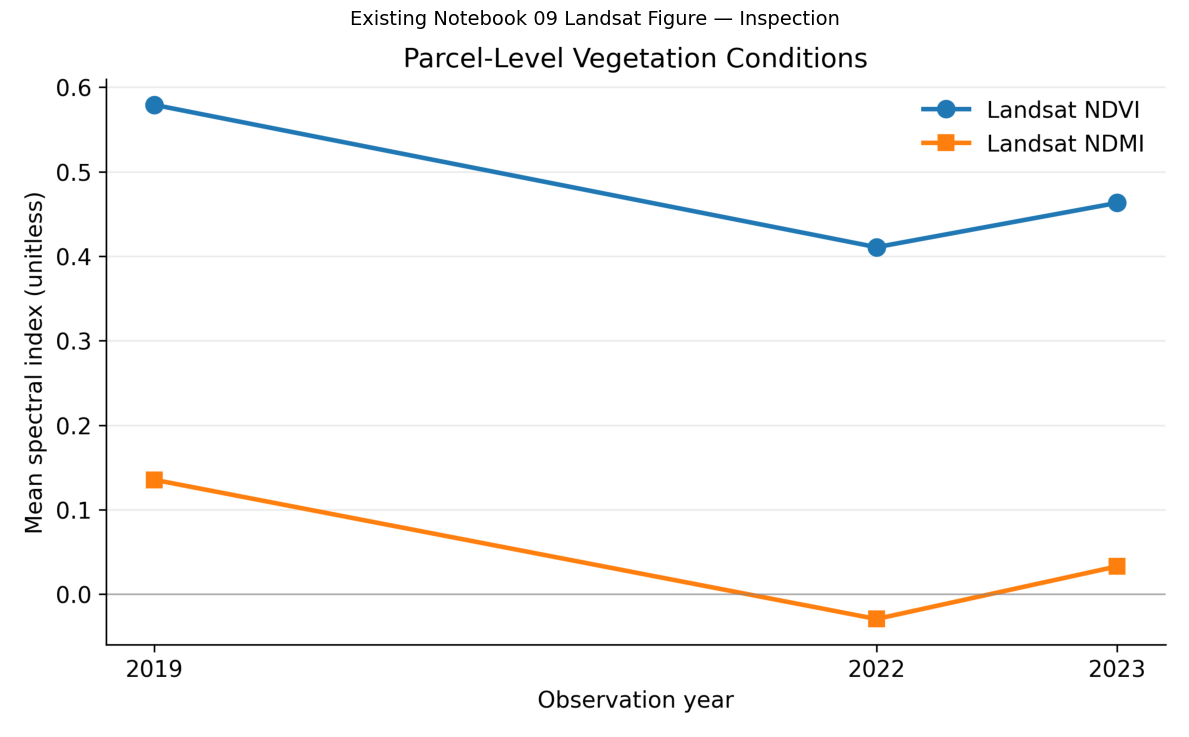


Inspection complete.
No original files modified.


In [14]:

# ============================================================
# SA 20 — CELL 8
# INSPECT EXISTING LANDSAT FIGURE
# Read-only — no original files modified
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

figure_path = (
    project
    / "Notebooks/sa18_7_dissertation_figures"
    / "figure_1_landsat_parcel_vegetation.png"
)

if not figure_path.exists():
    raise FileNotFoundError(figure_path)

with Image.open(figure_path) as img:
    print("Image:", figure_path.name)
    print("Dimensions:", img.size)
    print("Color mode:", img.mode)
    image = img.copy()

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(image)
ax.axis("off")
ax.set_title(
    "Existing Notebook 09 Landsat Figure — Inspection",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("\nInspection complete.")
print("No original files modified.")


ATE_MACOKE — EXISTING LANDSAT FIGURE
File: figure_1_landsat_parcel_vegetation.png



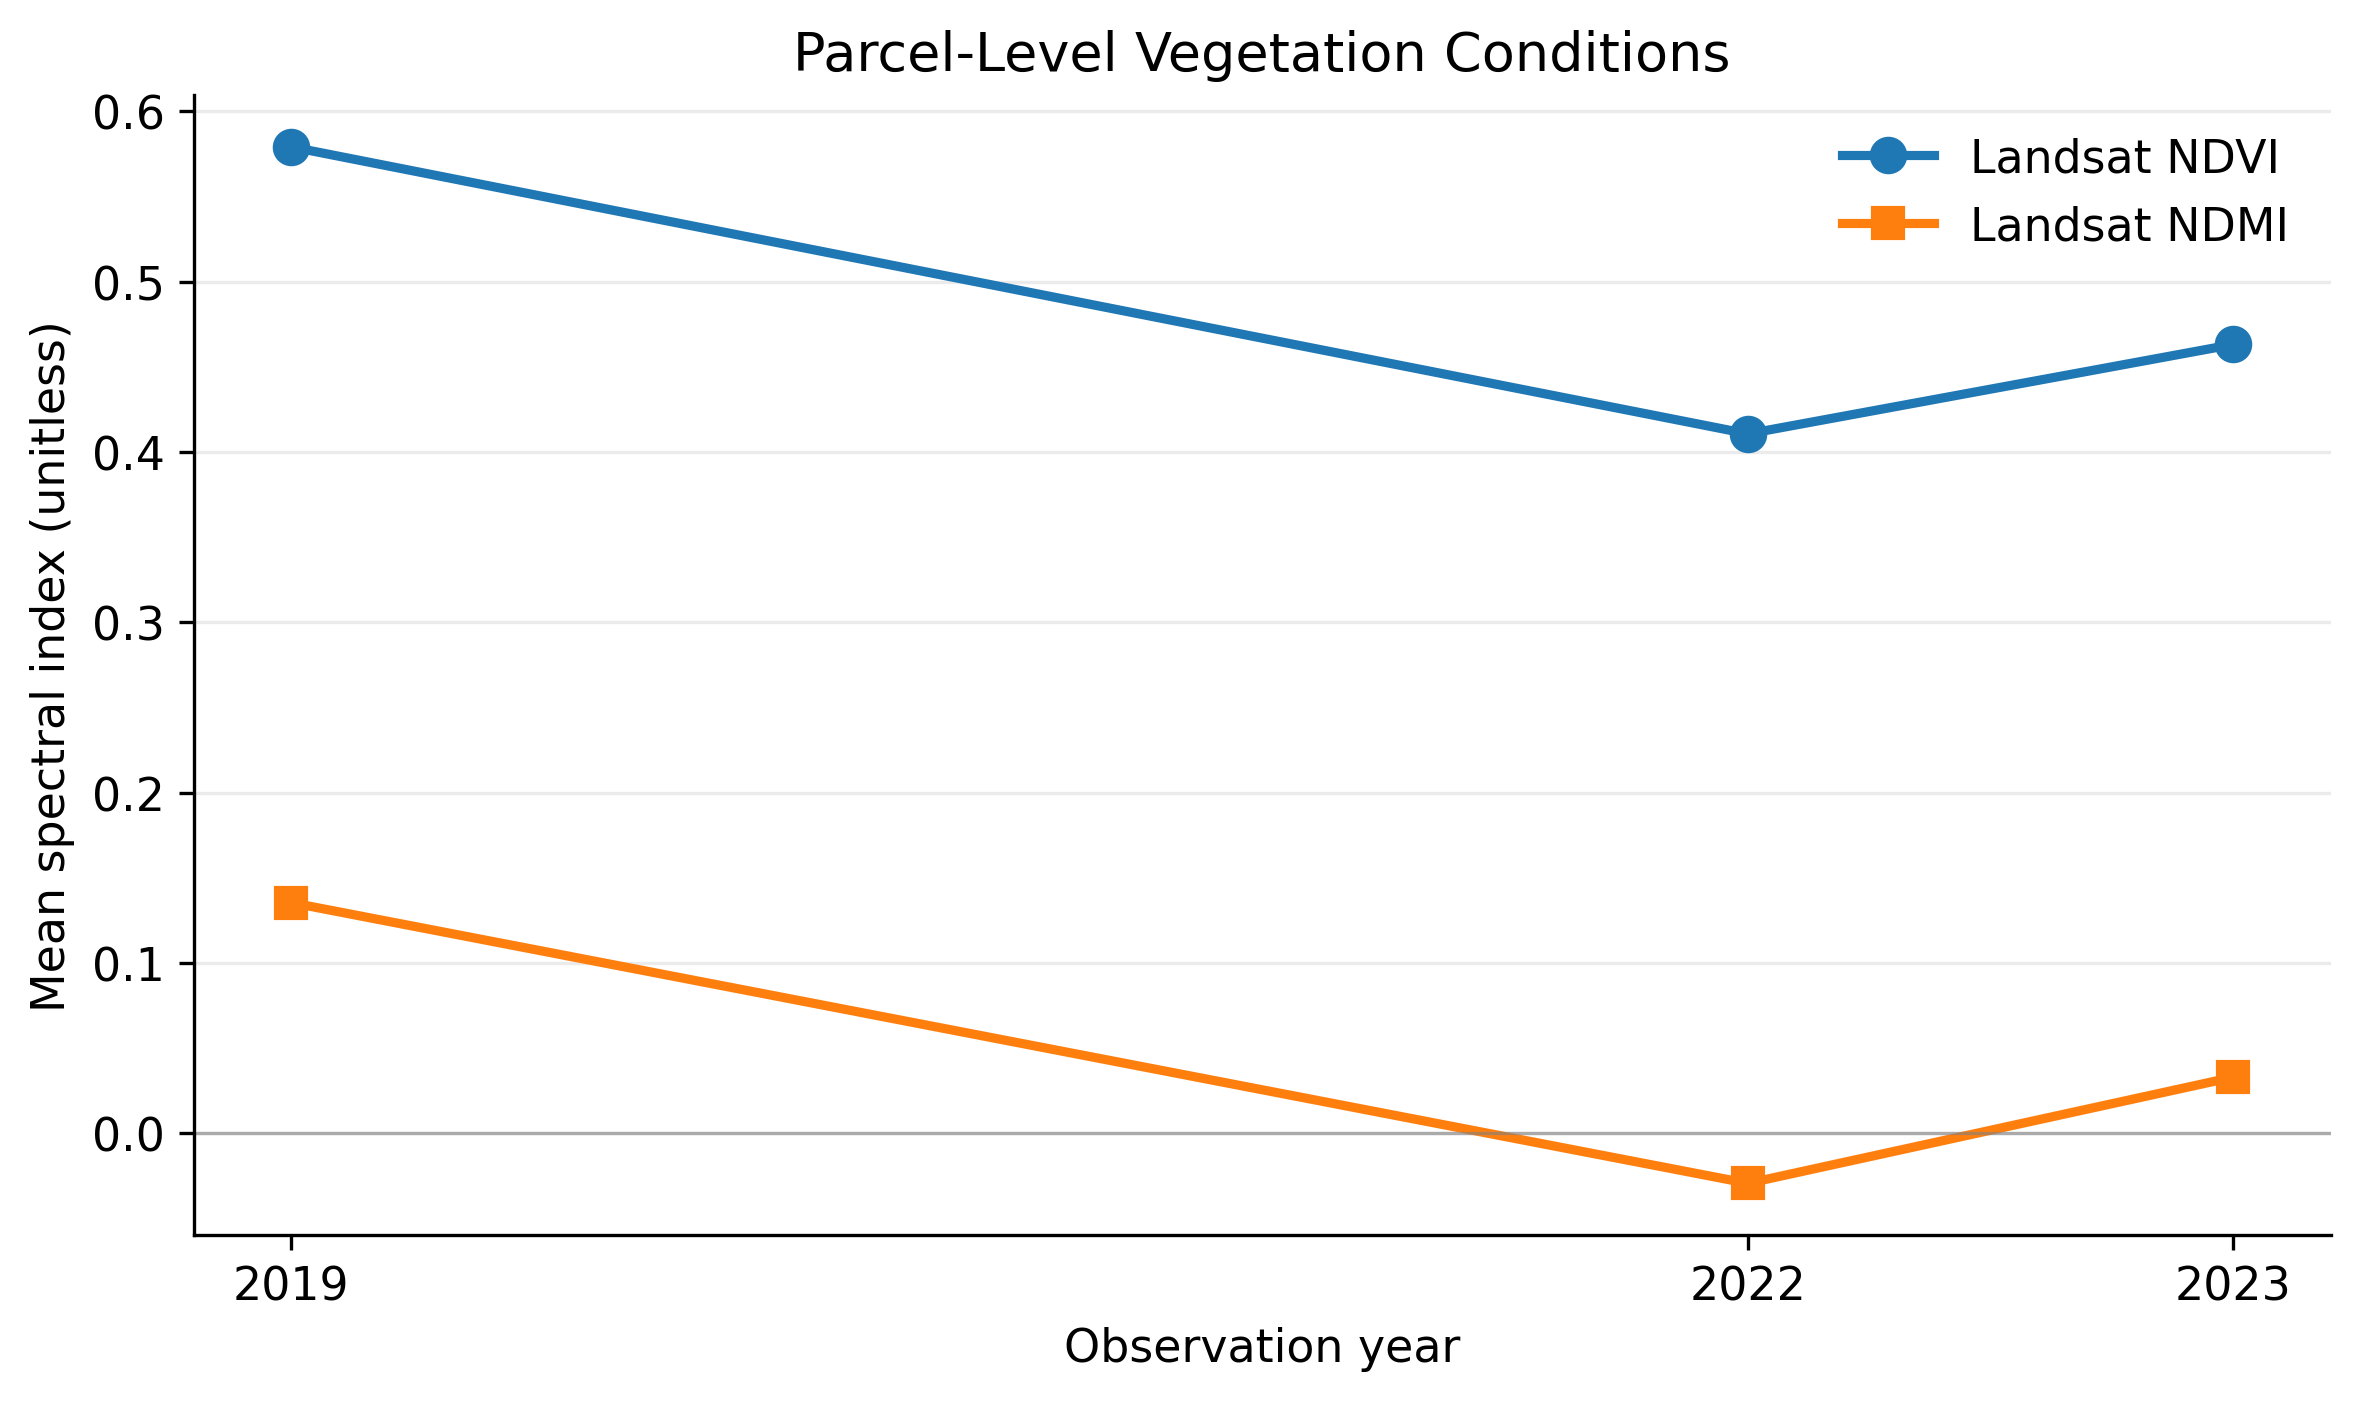


Image displayed above.


In [15]:

# ============================================================
# SA 20 — CELL 8 (REVISED)
# DISPLAY EXISTING LANDSAT FIGURE DIRECTLY IN JUPYTER
# ============================================================

from pathlib import Path
from IPython.display import display, Image

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

figure_path = (
    project
    / "Notebooks/sa18_7_dissertation_figures"
    / "figure_1_landsat_parcel_vegetation.png"
)

if not figure_path.exists():
    raise FileNotFoundError(figure_path)

print("ATE_MACOKE — EXISTING LANDSAT FIGURE")
print("File:", figure_path.name)
print()

# Force image to render as a Jupyter cell output
display(
    Image(
        filename=str(figure_path),
        width=1100,
        embed=True
    )
)

print("\nImage displayed above.")


In [16]:

# ============================================================
# SA 20 — CELL 9
# FIND ORIGINAL LANDSAT SCENE RETRIEVAL CODE
# Read-only inspection of Notebook 09
# ============================================================

from pathlib import Path
import json

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

notebook09 = (
    project
    / "Notebooks/09_dissertation_data_cube_validation.ipynb"
)

with open(notebook09, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "def find_scenes",
    "def read_band",
    "planetarycomputer.microsoft.com",
    "planetary_computer.sign",
    "landsat-c2-l2"
]

print("LANDSAT SOURCE CODE LOCATIONS")
print("=" * 65)

for i, cell in enumerate(nb["cells"]):

    source = "".join(cell.get("source", []))

    if any(keyword in source for keyword in keywords):

        print(f"\nNOTEBOOK 09 — CELL {i}")
        print("-" * 65)

        lines = source.splitlines()

        for j, line in enumerate(lines):
            if any(keyword in line for keyword in keywords):
                start = max(0, j - 3)
                end = min(len(lines), j + 12)

                for k in range(start, end):
                    print(f"{k+1:03d}: {lines[k]}")

                print()

print("\nInspection complete.")
print("Original Notebook 09 unchanged.")


LANDSAT SOURCE CODE LOCATIONS

NOTEBOOK 09 — CELL 216
-----------------------------------------------------------------
006: print("QA 11 — STEP 11J: HISTORICAL MODIS EVI INVENTORY")
007: print("=" * 75)
008: 
009: STAC_URL = "https://planetarycomputer.microsoft.com/api/stac/v1"
010: COLLECTION = "modis-13Q1-061"
011: 
012: # Use the validated local Pine Ridge Reservation boundary
013: reservation_geometry = (
014:     boundary.to_crs("EPSG:4326").geometry.iloc[0]
015: )
016: 
017: catalog = Client.open(STAC_URL)
018: 
019: search = catalog.search(
020:     collections=[COLLECTION],


NOTEBOOK 09 — CELL 219
-----------------------------------------------------------------
020: )
021: 
022: # Sign asset URLs for access
023: signed_item = planetary_computer.sign(test_item)
024: 
025: evi_url = signed_item.assets["250m_16_days_EVI"].href
026: reliability_url = signed_item.assets[
027:     "250m_16_days_pixel_reliability"
028: ].href
029: 
030: # Use the validated local reservation boundar

Candidate Landsat scenes: 5

SELECTED LANDSAT SCENE
Scene ID: LC08_L2SP_032030_20230830_02_T1
Acquisition: 2023-08-30T17:30:19.255724Z
Scene cloud cover: 0.0


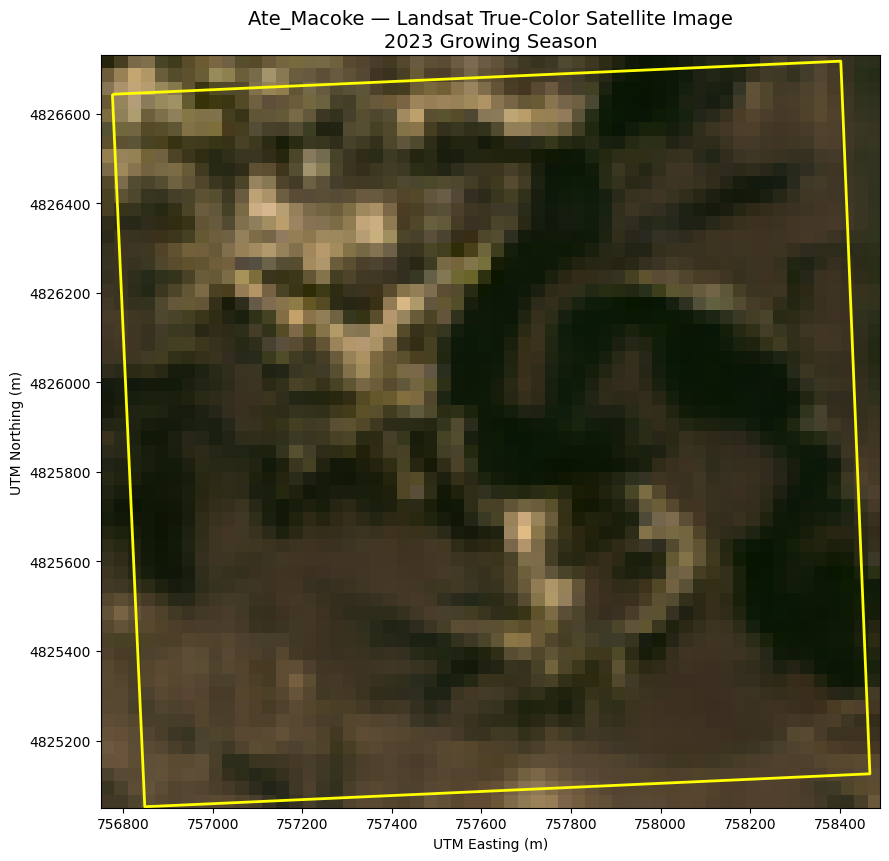


Real Landsat satellite background displayed.
No NDVI or NDMI recalculated.


In [29]:

# ============================================================
# SA 20 — CELL 10
# RETRIEVE REAL LANDSAT RGB SATELLITE IMAGE
# ATE_MACOKE | 2023 GROWING SEASON
#
# Does NOT recalculate NDVI or NDMI.
# Does NOT modify Notebook 09.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import planetary_computer

from pystac_client import Client
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

output_dir = project / "results/SA20_satellite_maps"
output_dir.mkdir(parents=True, exist_ok=True)

classification_path = (
    output_dir
    / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

parcel_path = (
    project / "data/ate_parcel_wanzi.shp"
)

# ------------------------------------------------------------
# 1. USE EXACT CLASSIFICATION RASTER GRID
# ------------------------------------------------------------

with rasterio.open(classification_path) as src:
    target_crs = src.crs
    target_transform = src.transform
    width = src.width
    height = src.height
    bounds = src.bounds

parcel = gpd.read_file(parcel_path)

if parcel.crs is None:
    raise ValueError("Parcel boundary has no CRS.")

parcel_wgs84 = parcel.to_crs("EPSG:4326")
bbox = parcel_wgs84.total_bounds.tolist()

# ------------------------------------------------------------
# 2. FIND LANDSAT 8/9 SCENES FROM 2023
# ------------------------------------------------------------

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

search = catalog.search(
    collections=["landsat-c2-l2"],
    bbox=bbox,
    datetime="2023-07-01/2023-08-31",
    query={"eo:cloud_cover": {"lt": 30}}
)

scenes = [
    item for item in search.items()
    if item.properties.get("platform")
    in ["landsat-8", "landsat-9"]
    and all(
        band in item.assets
        for band in ["red", "green", "blue"]
    )
]

scenes.sort(
    key=lambda item: item.properties.get(
        "eo:cloud_cover", 100
    )
)

print("Candidate Landsat scenes:", len(scenes))

if not scenes:
    raise RuntimeError(
        "No suitable July–August scenes found. "
        "Try May–September or a higher cloud threshold."
    )

# ------------------------------------------------------------
# 3. READ SATELLITE RGB BANDS
# ------------------------------------------------------------

def read_rgb_band(url):
    with rasterio.open(url) as src:
        with WarpedVRT(
            src,
            crs=target_crs,
            transform=target_transform,
            width=width,
            height=height,
            resampling=Resampling.bilinear
        ) as vrt:
            return vrt.read(1)

# Try candidate scenes until one can be read.
rgb = None
chosen_scene = None

for item in scenes:

    try:
        signed = planetary_computer.sign(item)

        red = read_rgb_band(signed.assets["red"].href)
        green = read_rgb_band(signed.assets["green"].href)
        blue = read_rgb_band(signed.assets["blue"].href)

        rgb_dn = np.stack(
            [red, green, blue],
            axis=-1
        ).astype("float32")

        # Landsat Collection 2 Level-2 scaling
        reflectance = rgb_dn * 0.0000275 - 0.2

        # Display stretch only — not NDVI processing
        rgb = np.clip(
            (reflectance - 0.02) / 0.30,
            0,
            1
        )

        chosen_scene = item
        break

    except Exception as exc:
        print(
            "Scene unavailable:",
            item.id,
            str(exc)[:120]
        )

if rgb is None:
    raise RuntimeError(
        "Unable to read RGB bands from candidate scenes."
    )

print("\nSELECTED LANDSAT SCENE")
print("Scene ID:", chosen_scene.id)
print(
    "Acquisition:",
    chosen_scene.properties.get("datetime")
)
print(
    "Scene cloud cover:",
    chosen_scene.properties.get("eo:cloud_cover")
)

# ------------------------------------------------------------
# 4. DISPLAY THE ACTUAL SATELLITE IMAGE
# ------------------------------------------------------------

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

fig, ax = plt.subplots(figsize=(9, 9))

ax.imshow(
    rgb,
    extent=extent,
    origin="upper"
)

parcel_utm = parcel.to_crs(target_crs)

parcel_utm.boundary.plot(
    ax=ax,
    edgecolor="yellow",
    linewidth=2
)

ax.set_title(
    "Ate_Macoke — Landsat True-Color Satellite Image\n"
    "2023 Growing Season",
    fontsize=14
)

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_aspect("equal")
ax.ticklabel_format(style="plain", useOffset=False)

plt.tight_layout()
plt.show()

print("\nReal Landsat satellite background displayed.")
print("No NDVI or NDMI recalculated.")


Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Satellite_Three_Class_Map.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Satellite_Three_Class_Map.pdf


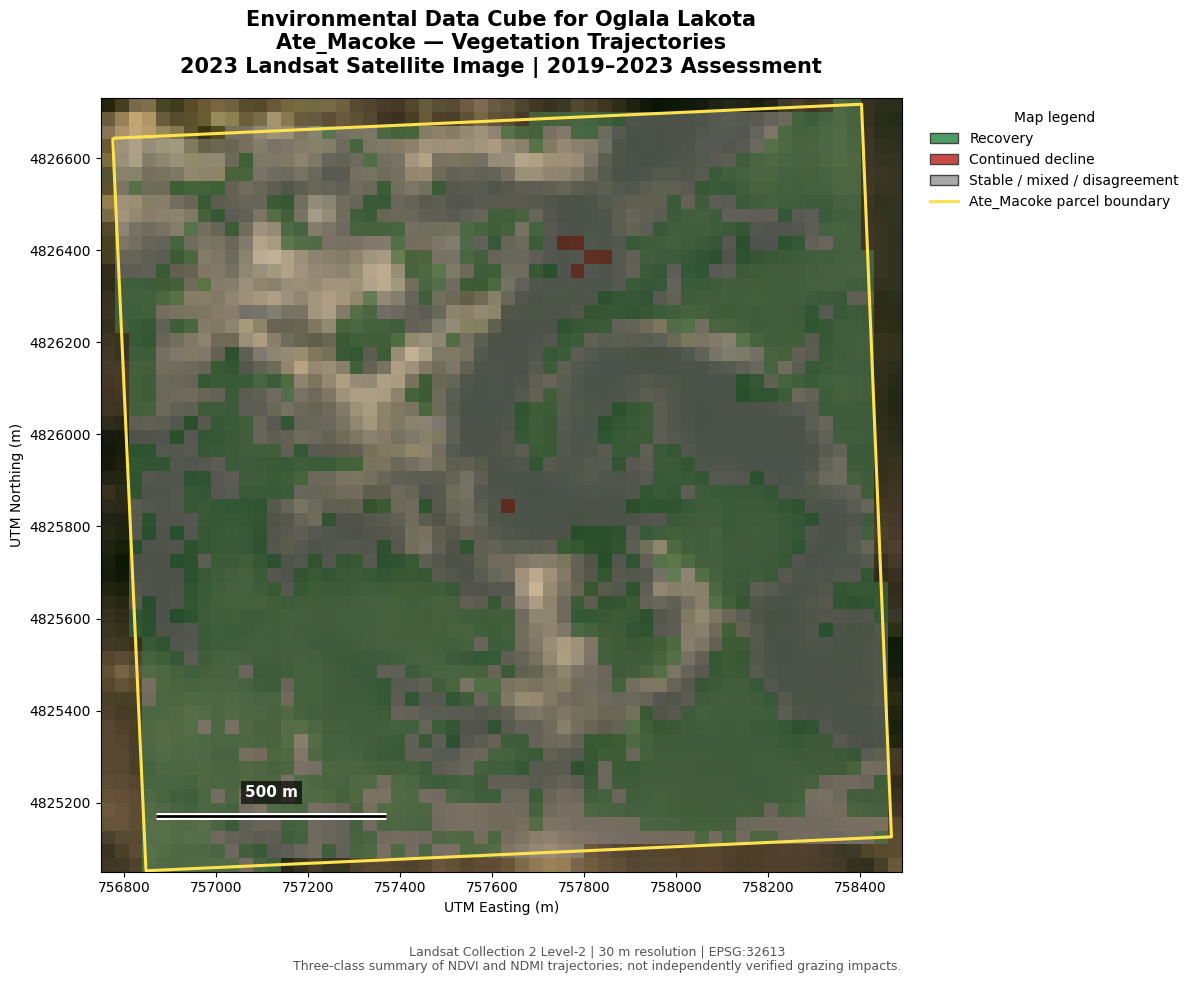


SA 20 — SATELLITE VEGETATION MAP COMPLETE
Original data and Notebook 09 unchanged.


In [18]:

# ============================================================
# SA 20 — CELL 11
# ATE_MACOKE — SATELLITE + THREE-CLASS VEGETATION MAP
# Environmental Data Cube for Oglala Lakota
#
# Background: 2023 Landsat true-color image (Cell 10)
# Overlay: Existing 2019–2023 three-class raster
#
# No NDVI recalculation.
# Original Notebook 09 and raster files unchanged.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY AND EXISTING RASTER
# ------------------------------------------------------------

output_dir = (
    project / "results/SA20_satellite_maps"
)

three_class_path = (
    output_dir
    / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

with rasterio.open(three_class_path) as src:

    vegetation = src.read(1, masked=True)
    bounds = src.bounds
    map_crs = src.crs

    extent = [
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ]

    raster_shape = (src.height, src.width)

# Check that the satellite image is aligned
if rgb.shape[:2] != raster_shape:
    raise ValueError(
        "Satellite RGB and vegetation raster "
        "have different grid dimensions."
    )

# ------------------------------------------------------------
# 2. THREE-CLASS COLOR SCHEME
# ------------------------------------------------------------

labels = {
    1: "Recovery",
    2: "Continued decline",
    3: "Stable / mixed / disagreement"
}

colors = [
    "#4B9B62",  # Recovery
    "#C84A42",  # Continued decline
    "#A7A7A7"   # Stable / mixed / disagreement
]

cmap = ListedColormap(colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    cmap.N
)

# ------------------------------------------------------------
# 3. CREATE THE SATELLITE MAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

# Real Landsat background
ax.imshow(
    rgb,
    extent=extent,
    origin="upper",
    interpolation="nearest",
    zorder=1
)

# Three-class vegetation overlay
ax.imshow(
    vegetation,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    alpha=0.42,
    interpolation="nearest",
    zorder=2
)

# Actual parcel boundary
parcel_utm = parcel.to_crs(map_crs)

parcel_utm.boundary.plot(
    ax=ax,
    edgecolor="#FFE34D",
    linewidth=2.2,
    zorder=3
)

# ------------------------------------------------------------
# 4. LEGEND
# ------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor=colors[i - 1],
        edgecolor="#444444",
        label=labels[i]
    )
    for i in [1, 2, 3]
]

legend_handles.append(
    Line2D(
        [0], [0],
        color="#FFE34D",
        linewidth=2.2,
        label="Ate_Macoke parcel boundary"
    )
)

ax.legend(
    handles=legend_handles,
    title="Map legend",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=10
)

# ------------------------------------------------------------
# 5. SCALE BAR — UTM METERS
# ------------------------------------------------------------

scale_length = 500  # meters

x0 = bounds.left + 120
y0 = bounds.bottom + 120

ax.plot(
    [x0, x0 + scale_length],
    [y0, y0],
    color="white",
    linewidth=5,
    solid_capstyle="butt",
    zorder=5
)

ax.plot(
    [x0, x0 + scale_length],
    [y0, y0],
    color="black",
    linewidth=2,
    solid_capstyle="butt",
    zorder=6
)

ax.text(
    x0 + scale_length / 2,
    y0 + 35,
    "500 m",
    ha="center",
    va="bottom",
    color="white",
    fontsize=11,
    fontweight="bold",
    bbox={
        "facecolor": "black",
        "alpha": 0.65,
        "edgecolor": "none",
        "pad": 3
    },
    zorder=7
)

# ------------------------------------------------------------
# 6. TITLES AND LABELS
# ------------------------------------------------------------

ax.set_title(
    "Environmental Data Cube for Oglala Lakota\n"
    "Ate_Macoke — Vegetation Trajectories\n"
    "2023 Landsat Satellite Image | 2019–2023 Assessment",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_aspect("equal")
ax.ticklabel_format(style="plain", useOffset=False)

fig.text(
    0.5,
    0.025,
    "Landsat Collection 2 Level-2 | "
    "30 m resolution | EPSG:32613\n"
    "Three-class summary of NDVI and NDMI trajectories; "
    "not independently verified grazing impacts.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# ------------------------------------------------------------
# 7. EXPORT FIGURE WITHOUT OVERWRITING
# ------------------------------------------------------------

for extension in ["png", "pdf"]:

    base_path = (
        output_dir
        / f"Ate_Macoke_Satellite_Three_Class_Map.{extension}"
    )

    export_path = base_path
    version = 2

    while export_path.exists():

        export_path = (
            output_dir
            / (
                "Ate_Macoke_Satellite_Three_Class_Map"
                f"_v{version}.{extension}"
            )
        )

        version += 1

    fig.savefig(
        export_path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", export_path)

plt.show()

print("\nSA 20 — SATELLITE VEGETATION MAP COMPLETE")
print("Original data and Notebook 09 unchanged.")


Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Professional_Satellite_Vegetation_Map.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Professional_Satellite_Vegetation_Map.pdf


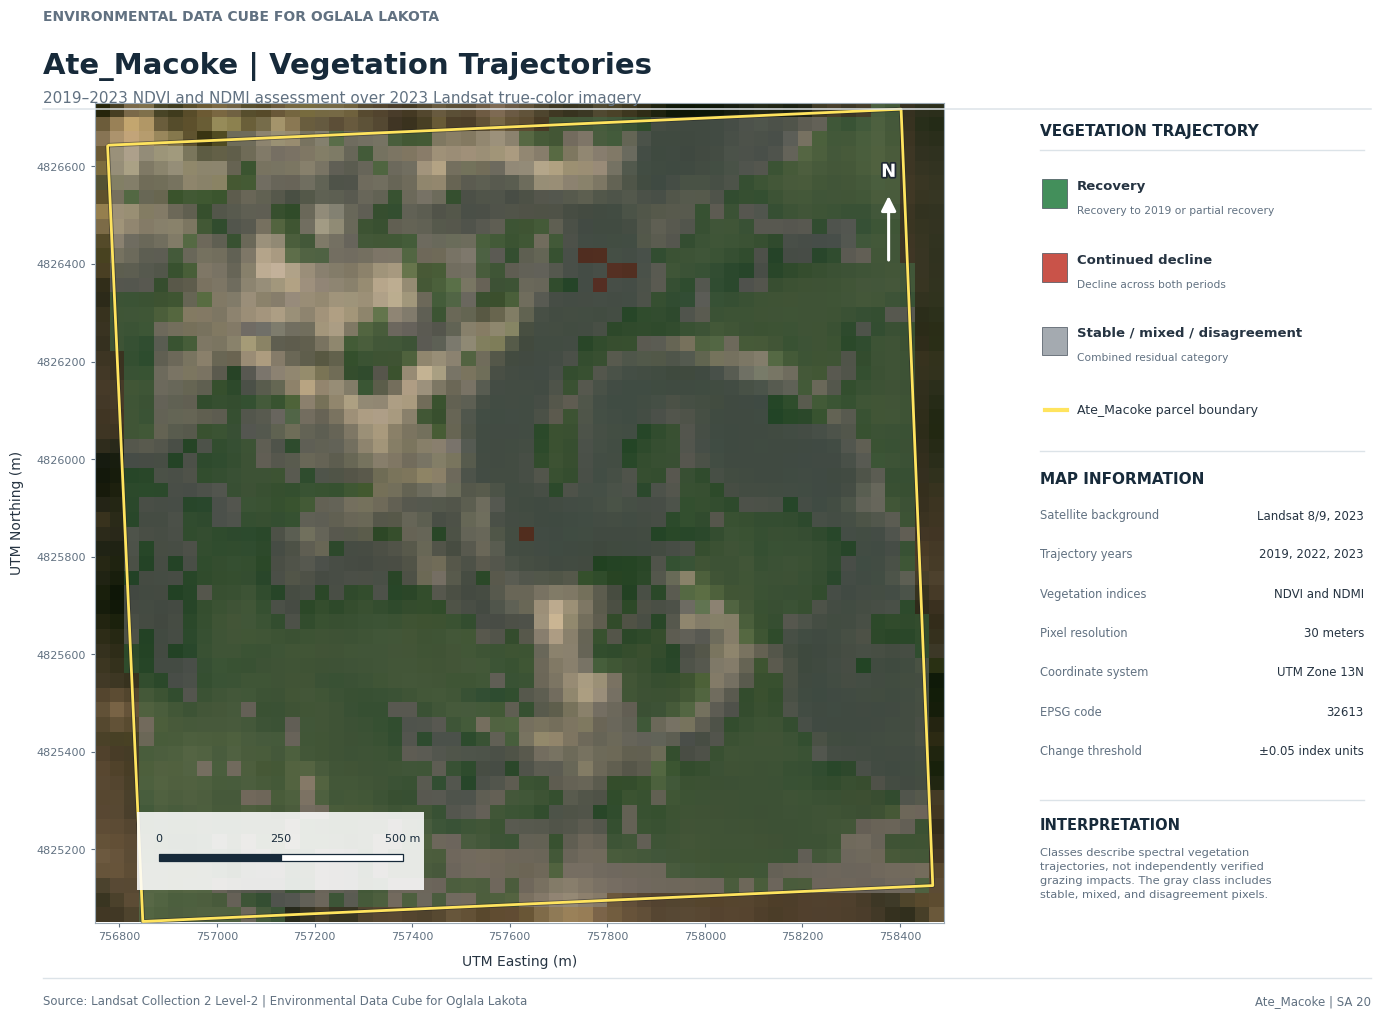


SA 20 — PROFESSIONAL SATELLITE MAP COMPLETE
Original Notebook 09 unchanged.
Original six-class raster unchanged.
Three-class classification values unchanged.


In [19]:

# ================================================================
# SA 20 — CELL 11 (REVISED)
# PROFESSIONAL ATE_MACOKE SATELLITE VEGETATION MAP
#
# Environmental Data Cube for Oglala Lakota
#
# BACKGROUND: Actual 2023 Landsat RGB from Cell 10
# OVERLAY: Existing 2019–2023 three-class raster
# BOUNDARY: Actual Ate_Macoke parcel shapefile
#
# Outputs: 400 DPI PNG + vector PDF
# Original data and Notebook 09 remain unchanged.
# ================================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import rasterio
import geopandas as gpd

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Patch, FancyArrowPatch
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

output_dir = project / "results/SA20_satellite_maps"
output_dir.mkdir(parents=True, exist_ok=True)

raster_path = (
    output_dir
    / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

if not raster_path.exists():
    raise FileNotFoundError(raster_path)

if not parcel_path.exists():
    raise FileNotFoundError(parcel_path)

if "rgb" not in globals():
    raise RuntimeError(
        "The Landsat RGB image is not in memory. "
        "Run Cell 10 first, then run this cell."
    )

# ------------------------------------------------
# 2. READ THE EXISTING CLASSIFICATION
# ------------------------------------------------

with rasterio.open(raster_path) as src:

    vegetation = src.read(1, masked=True)
    bounds = src.bounds
    map_crs = src.crs
    raster_transform = src.transform

    raster_shape = (src.height, src.width)

    extent = [
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ]

if rgb.shape != (*raster_shape, 3):
    raise ValueError(
        f"RGB shape {rgb.shape} does not match "
        f"raster shape {raster_shape}."
    )

if map_crs is None or not map_crs.is_projected:
    raise ValueError(
        "A projected raster CRS is required for the scale bar."
    )

# RGB must be the image aligned to this raster grid
# from Cell 10.
rgb_display = np.clip(
    np.asarray(rgb, dtype=np.float32),
    0, 1
)

# ------------------------------------------------
# 3. LOAD PARCEL BOUNDARY
# ------------------------------------------------

parcel = gpd.read_file(parcel_path)

if parcel.crs is None:
    raise ValueError("Parcel boundary has no CRS.")

parcel_utm = parcel.to_crs(map_crs)

# ------------------------------------------------
# 4. DEFINE CARTOGRAPHIC STYLE
# ------------------------------------------------

NAVY = "#172A3A"
DARK = "#263442"
MUTED = "#617181"
LINE = "#DCE3E8"
WHITE = "#FFFFFF"

GREEN = "#438F5B"
RED = "#C95349"
GRAY = "#A4AAB0"
BOUNDARY = "#FFE45E"

class_labels = {
    1: "Recovery",
    2: "Continued decline",
    3: "Stable / mixed / disagreement"
}

class_colors = [
    GREEN,
    RED,
    GRAY
]

cmap = ListedColormap(class_colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    cmap.N
)

# Ensure NoData is transparent.
overlay = np.ma.masked_equal(
    vegetation.filled(255),
    255
)

# ------------------------------------------------
# 5. CREATE PROFESSIONAL PAGE LAYOUT
# ------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

fig = plt.figure(
    figsize=(15, 11),
    facecolor=WHITE
)

# Main map on the left
ax = fig.add_axes([
    0.075, 0.135,
    0.635, 0.745
])

# Right-side information panel
panel = fig.add_axes([
    0.735, 0.135,
    0.225, 0.745
])

panel.set_axis_off()
panel.set_xlim(0, 1)
panel.set_ylim(0, 1)

# ------------------------------------------------
# 6. PAGE HEADER
# ------------------------------------------------

fig.text(
    0.075, 0.965,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    fontsize=10,
    color=MUTED,
    weight="bold",
    va="top"
)

fig.text(
    0.075, 0.927,
    "Ate_Macoke | Vegetation Trajectories",
    fontsize=21,
    color=NAVY,
    weight="bold",
    va="top"
)

fig.text(
    0.075, 0.891,
    "2019–2023 NDVI and NDMI assessment "
    "over 2023 Landsat true-color imagery",
    fontsize=11,
    color=MUTED,
    va="top"
)

# Header rule
fig.add_artist(
    Line2D(
        [0.075, 0.96],
        [0.875, 0.875],
        transform=fig.transFigure,
        color=LINE,
        linewidth=1.1
    )
)

# ------------------------------------------------
# 7. LANDSAT SATELLITE BACKGROUND
# ------------------------------------------------

ax.imshow(
    rgb_display,
    extent=extent,
    origin="upper",
    interpolation="nearest",
    zorder=1
)

# ------------------------------------------------
# 8. TRANSPARENT THREE-CLASS OVERLAY
# ------------------------------------------------

overlay_alpha = 0.36

ax.imshow(
    overlay,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    alpha=overlay_alpha,
    interpolation="nearest",
    zorder=2
)

# ------------------------------------------------
# 9. PARCEL BOUNDARY
# ------------------------------------------------

parcel_utm.boundary.plot(
    ax=ax,
    color=BOUNDARY,
    linewidth=2.0,
    zorder=4
)

# Subtle dark outline makes yellow boundary
# visible against bright satellite pixels.
parcel_utm.boundary.plot(
    ax=ax,
    color="#222222",
    linewidth=3.2,
    alpha=0.50,
    zorder=3
)

# ------------------------------------------------
# 10. MAP FRAME AND COORDINATES
# ------------------------------------------------

ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)
ax.set_aspect("equal")

ax.set_xlabel(
    "UTM Easting (m)",
    fontsize=10,
    color=DARK,
    labelpad=9
)

ax.set_ylabel(
    "UTM Northing (m)",
    fontsize=10,
    color=DARK,
    labelpad=9
)

ax.tick_params(
    axis="both",
    labelsize=8,
    colors=MUTED,
    direction="out",
    length=3
)

formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)

for spine in ax.spines.values():
    spine.set_color("#9CAAB5")
    spine.set_linewidth(0.8)

# ------------------------------------------------
# 11. NORTH ARROW
# ------------------------------------------------

north_x = 0.935
north_y = 0.89

ax.annotate(
    "",
    xy=(north_x, north_y),
    xytext=(north_x, north_y - 0.085),
    xycoords="axes fraction",
    textcoords="axes fraction",
    arrowprops={
        "arrowstyle": "-|>",
        "color": WHITE,
        "lw": 2.2,
        "mutation_scale": 22
    },
    zorder=8
)

ax.text(
    north_x,
    north_y + 0.015,
    "N",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=13,
    fontweight="bold",
    color=WHITE,
    path_effects=[
        pe.withStroke(
            linewidth=2.5,
            foreground="#1F2933"
        )
    ],
    zorder=9
)

# ------------------------------------------------
# 12. SCALE BAR — 500 METERS
# ------------------------------------------------

# EPSG:32613 is in meters.
if map_crs.to_epsg() != 32613:
    raise ValueError(
        "This map's 500 m scale bar expects EPSG:32613."
    )

scale_length = 500
segment = scale_length / 2

map_width = bounds.right - bounds.left
map_height = bounds.top - bounds.bottom

x0 = bounds.left + map_width * 0.075
y0 = bounds.bottom + map_height * 0.075

bar_height = map_height * 0.009

# White backing for visibility
backing = Rectangle(
    (
        x0 - map_width * 0.025,
        y0 - map_height * 0.035
    ),
    scale_length + map_width * 0.05,
    map_height * 0.095,
    facecolor=WHITE,
    edgecolor="none",
    alpha=0.87,
    zorder=5
)

ax.add_patch(backing)

for i, color in enumerate([NAVY, WHITE]):

    rect = Rectangle(
        (x0 + i * segment, y0),
        segment,
        bar_height,
        facecolor=color,
        edgecolor=NAVY,
        linewidth=0.9,
        zorder=6
    )

    ax.add_patch(rect)

for x, label in [
    (x0, "0"),
    (x0 + segment, "250"),
    (x0 + scale_length, "500 m")
]:

    ax.text(
        x,
        y0 + bar_height + map_height * 0.012,
        label,
        ha="center",
        va="bottom",
        fontsize=8,
        color=NAVY,
        zorder=7
    )

# ------------------------------------------------
# 13. RIGHT PANEL — LEGEND
# ------------------------------------------------

panel.text(
    0.02, 0.975,
    "VEGETATION TRAJECTORY",
    fontsize=11,
    color=NAVY,
    weight="bold",
    va="top"
)

panel.plot(
    [0.02, 0.98],
    [0.943, 0.943],
    color=LINE,
    linewidth=1
)

legend_items = [
    (
        GREEN,
        "Recovery",
        "Recovery to 2019 or partial recovery"
    ),
    (
        RED,
        "Continued decline",
        "Decline across both periods"
    ),
    (
        GRAY,
        "Stable / mixed / disagreement",
        "Combined residual category"
    )
]

legend_y = [0.89, 0.80, 0.71]

for y, (color, label, detail) in zip(
    legend_y, legend_items
):

    panel.add_patch(
        Rectangle(
            (0.025, y - 0.018),
            0.075,
            0.035,
            facecolor=color,
            edgecolor="#46515C",
            linewidth=0.5
        )
    )

    panel.text(
        0.13, y + 0.009,
        label,
        fontsize=9.5,
        weight="bold",
        color=DARK,
        va="center"
    )

    panel.text(
        0.13, y - 0.021,
        detail,
        fontsize=7.7,
        color=MUTED,
        va="center"
    )

# Boundary legend
panel.plot(
    [0.035, 0.10],
    [0.625, 0.625],
    color=BOUNDARY,
    linewidth=3
)

panel.text(
    0.13, 0.625,
    "Ate_Macoke parcel boundary",
    fontsize=9,
    color=DARK,
    va="center"
)

# ------------------------------------------------
# 14. RIGHT PANEL — MAP INFORMATION
# ------------------------------------------------

panel.plot(
    [0.02, 0.98],
    [0.575, 0.575],
    color=LINE,
    linewidth=1
)

panel.text(
    0.02, 0.55,
    "MAP INFORMATION",
    fontsize=11,
    color=NAVY,
    weight="bold",
    va="top"
)

details = [
    ("Satellite background", "Landsat 8/9, 2023"),
    ("Trajectory years", "2019, 2022, 2023"),
    ("Vegetation indices", "NDVI and NDMI"),
    ("Pixel resolution", "30 meters"),
    ("Coordinate system", "UTM Zone 13N"),
    ("EPSG code", "32613"),
    ("Change threshold", "±0.05 index units")
]

y = 0.505

for heading, value in details:

    panel.text(
        0.02, y,
        heading,
        fontsize=8.3,
        color=MUTED,
        va="top"
    )

    panel.text(
        0.98, y,
        value,
        fontsize=8.5,
        color=DARK,
        weight="medium",
        va="top",
        ha="right"
    )

    y -= 0.048

# ------------------------------------------------
# 15. RIGHT PANEL — INTERPRETATION
# ------------------------------------------------

panel.plot(
    [0.02, 0.98],
    [0.15, 0.15],
    color=LINE,
    linewidth=1
)

panel.text(
    0.02, 0.128,
    "INTERPRETATION",
    fontsize=10.5,
    color=NAVY,
    weight="bold",
    va="top"
)

panel.text(
    0.02, 0.091,
    "Classes describe spectral vegetation\n"
    "trajectories, not independently verified\n"
    "grazing impacts. The gray class includes\n"
    "stable, mixed, and disagreement pixels.",
    fontsize=8.2,
    color=MUTED,
    va="top",
    linespacing=1.5
)

# ------------------------------------------------
# 16. FOOTER
# ------------------------------------------------

fig.add_artist(
    Line2D(
        [0.075, 0.96],
        [0.085, 0.085],
        transform=fig.transFigure,
        color=LINE,
        linewidth=1
    )
)

fig.text(
    0.075, 0.060,
    "Source: Landsat Collection 2 Level-2 | "
    "Environmental Data Cube for Oglala Lakota",
    fontsize=8.5,
    color=MUTED
)

fig.text(
    0.96, 0.060,
    "Ate_Macoke | SA 20",
    fontsize=8.5,
    color=MUTED,
    ha="right"
)

# ------------------------------------------------
# 17. EXPORT — NEVER OVERWRITE EXISTING MAPS
# ------------------------------------------------

base_name = (
    "Ate_Macoke_Professional_Satellite_"
    "Vegetation_Map"
)

for extension in ["png", "pdf"]:

    export_path = (
        output_dir / f"{base_name}.{extension}"
    )

    version = 2

    while export_path.exists():

        export_path = (
            output_dir
            / f"{base_name}_v{version}.{extension}"
        )

        version += 1

    fig.savefig(
        export_path,
        dpi=400,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.18
    )

    print("Saved:", export_path)

plt.show()

print("\n" + "=" * 65)
print("SA 20 — PROFESSIONAL SATELLITE MAP COMPLETE")
print("=" * 65)
print("Original Notebook 09 unchanged.")
print("Original six-class raster unchanged.")
print("Three-class classification values unchanged.")


Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Refined_Satellite_Map.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Refined_Satellite_Map.pdf


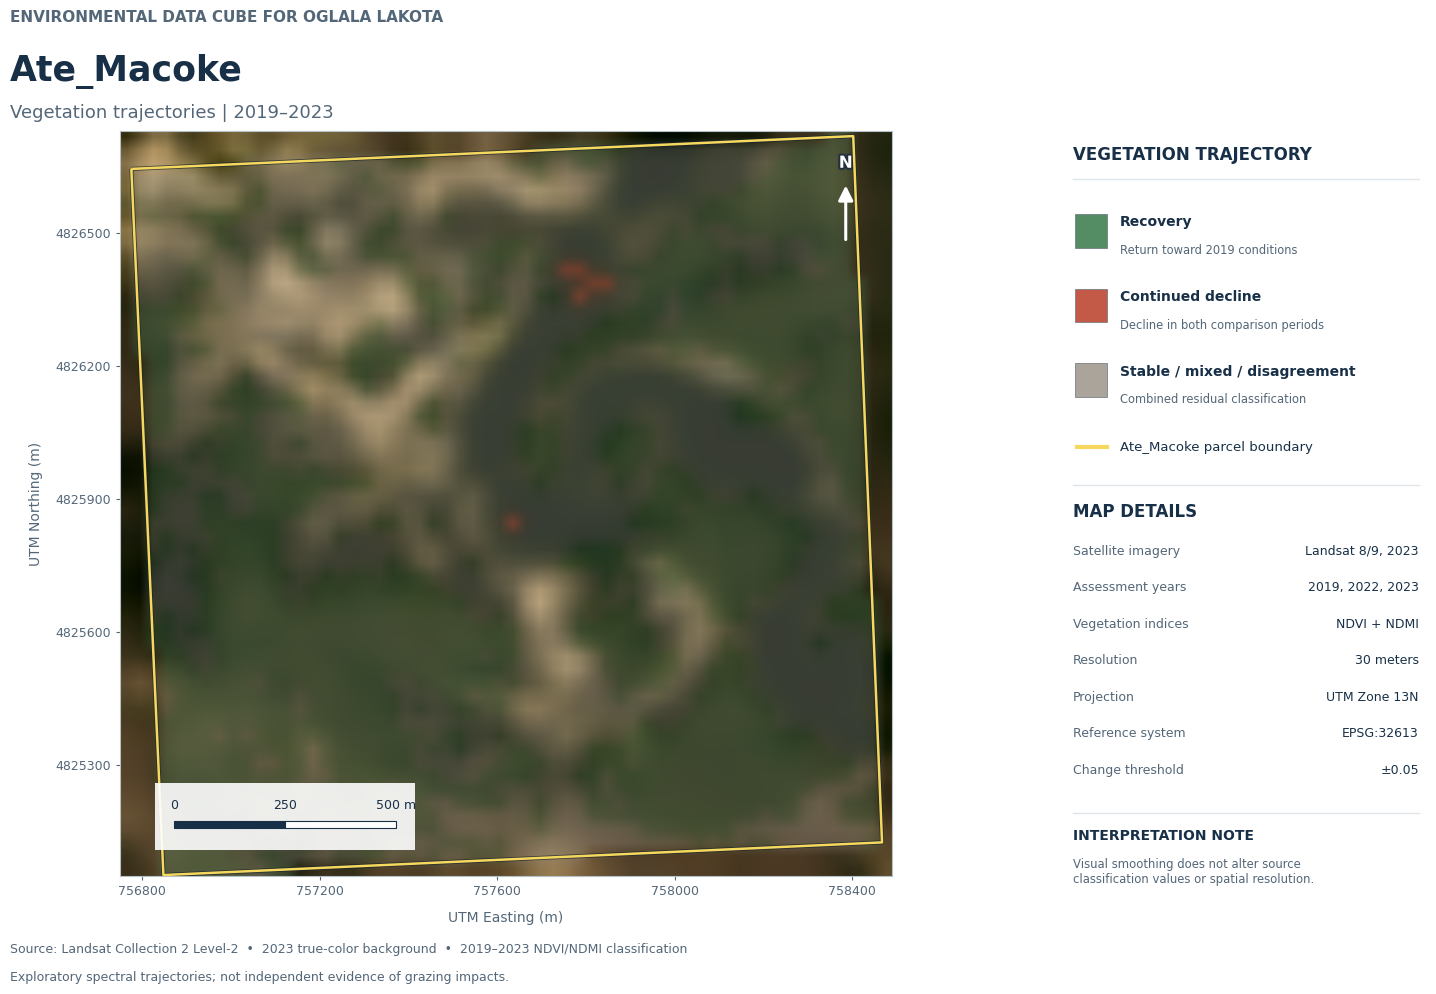


REFINED MAP COMPLETE
Source classification and GIS files unchanged.


In [20]:

# ============================================================
# SA 20 — CELL 12
# ATE_MACOKE — REFINED DISSERTATION SATELLITE MAP
#
# Real Landsat RGB + existing three-class classification
# Smoothing affects DISPLAY ONLY, not GIS source values.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import rasterio
import geopandas as gpd

from scipy.ndimage import gaussian_filter
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator, ScalarFormatter

# ------------------------------------------------------------
# 1. LOAD ORIGINAL DATA
# ------------------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

raster_file = (
    out / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

parcel_file = project / "data/ate_parcel_wanzi.shp"

if "rgb" not in globals():
    raise RuntimeError("Run Cell 10 first to load Landsat RGB.")

with rasterio.open(raster_file) as src:
    classes = src.read(1, masked=True)
    bounds = src.bounds
    crs = src.crs
    shape = (src.height, src.width)

if rgb.shape != (*shape, 3):
    raise ValueError("RGB and classification grids do not match.")

if crs.to_epsg() != 32613:
    raise ValueError("Expected EPSG:32613 for the map scale.")

parcel = gpd.read_file(parcel_file).to_crs(crs)

extent = [
    bounds.left, bounds.right,
    bounds.bottom, bounds.top
]

# ------------------------------------------------------------
# 2. PRESENTATION SETTINGS
# ------------------------------------------------------------

# Adjust these values if desired.
RGB_SMOOTHING = 0.65
RGB_CONTRAST = 1.12
OVERLAY_OPACITY = 0.33
OVERLAY_EDGE_SOFTNESS = 0.55

# Muted, natural colors
COLORS = {
    1: "#548C63",  # Sage green: recovery
    2: "#C35A47",  # Terracotta: continued decline
    3: "#AAA49B"   # Warm gray: mixed/uncertain
}

INK = "#183047"
SECONDARY = "#546778"
LIGHT = "#DFE5E9"
BOUNDARY = "#F5D85D"

# ------------------------------------------------------------
# 3. ENHANCE LANDSAT BACKGROUND
# ------------------------------------------------------------

# Mild blur reduces pixel harshness without inventing detail.
rgb_smooth = gaussian_filter(
    np.asarray(rgb, dtype=np.float32),
    sigma=(RGB_SMOOTHING, RGB_SMOOTHING, 0)
)

# Subtle contrast and brightness adjustment
rgb_smooth = (
    (rgb_smooth - 0.5) * RGB_CONTRAST + 0.5
)

rgb_smooth = np.clip(rgb_smooth, 0, 1)

# ------------------------------------------------------------
# 4. PREPARE DISPLAY-ONLY CLASS OVERLAY
# ------------------------------------------------------------

# Smooth only the visual alpha masks.
# The underlying class values remain unchanged.

valid = ~np.ma.getmaskarray(classes)
class_data = np.asarray(classes.data)

def hex_to_rgb(value):
    return np.array([
        int(value[i:i+2], 16) / 255
        for i in (1, 3, 5)
    ], dtype=float)

# Start with original satellite colors
composite = rgb_smooth.copy()

# Draw each class separately, keeping red decline visible.
for class_id in [3, 1, 2]:

    mask = (
        valid & (class_data == class_id)
    ).astype(float)

    # For display only: soften boundaries slightly.
    alpha = gaussian_filter(
        mask,
        sigma=OVERLAY_EDGE_SOFTNESS
    )

    # Restrict the overlay to valid classified areas.
    alpha *= valid

    # Keep tiny decline areas visible.
    if class_id == 2:
        alpha = np.maximum(
            alpha,
            mask * 0.68
        )

    alpha = np.clip(
        alpha * OVERLAY_OPACITY
        if class_id != 2
        else alpha * 0.75,
        0, 0.75
    )

    color = hex_to_rgb(COLORS[class_id])

    composite = (
        composite * (1 - alpha[..., None])
        + color[None, None, :] * alpha[..., None]
    )

composite = np.clip(composite, 0, 1)

# ------------------------------------------------------------
# 5. CREATE LARGE, CLEAN LAYOUT
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "pdf.fonttype": 42
})

fig = plt.figure(
    figsize=(16, 10.5),
    facecolor="white"
)

# Separate axes prevent the title, map, and legend
# from overlapping.
ax = fig.add_axes([0.075, 0.14, 0.62, 0.71])
info = fig.add_axes([0.735, 0.14, 0.225, 0.71])

info.set_axis_off()
info.set_xlim(0, 1)
info.set_ylim(0, 1)

# ------------------------------------------------------------
# 6. HEADER
# ------------------------------------------------------------

fig.text(
    0.075, 0.965,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    color=SECONDARY,
    fontsize=11,
    weight="bold",
    va="top"
)

fig.text(
    0.075, 0.923,
    "Ate_Macoke",
    color=INK,
    fontsize=25,
    weight="bold",
    va="top"
)

fig.text(
    0.075, 0.875,
    "Vegetation trajectories | 2019–2023",
    color=SECONDARY,
    fontsize=13,
    va="top"
)

# ------------------------------------------------------------
# 7. DRAW THE MAP
# ------------------------------------------------------------

ax.imshow(
    composite,
    extent=extent,
    origin="upper",
    interpolation="bilinear"
)

# Dark halo followed by thin gold boundary
parcel.boundary.plot(
    ax=ax,
    color="#18242D",
    linewidth=3.0,
    alpha=0.7,
    zorder=5
)

parcel.boundary.plot(
    ax=ax,
    color=BOUNDARY,
    linewidth=1.8,
    zorder=6
)

ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)
ax.set_aspect("equal")

ax.set_xlabel(
    "UTM Easting (m)",
    color=SECONDARY,
    fontsize=10,
    labelpad=9
)

ax.set_ylabel(
    "UTM Northing (m)",
    color=SECONDARY,
    fontsize=10,
    labelpad=9
)

ax.xaxis.set_major_locator(MaxNLocator(5))
ax.yaxis.set_major_locator(MaxNLocator(6))

fmt = ScalarFormatter(useOffset=False)
fmt.set_scientific(False)
ax.xaxis.set_major_formatter(fmt)
ax.yaxis.set_major_formatter(fmt)

ax.tick_params(
    labelsize=9,
    colors=SECONDARY,
    length=3
)

for spine in ax.spines.values():
    spine.set_color("#B5C0C7")
    spine.set_linewidth(0.8)

# ------------------------------------------------------------
# 8. NORTH INDICATOR
# ------------------------------------------------------------

ax.annotate(
    "",
    xy=(0.94, 0.93),
    xytext=(0.94, 0.85),
    xycoords="axes fraction",
    arrowprops=dict(
        arrowstyle="-|>",
        color="white",
        linewidth=2.2,
        mutation_scale=22
    )
)

ax.text(
    0.94, 0.95, "N",
    transform=ax.transAxes,
    color="white",
    ha="center",
    fontsize=12,
    weight="bold",
    path_effects=[
        pe.withStroke(
            linewidth=3,
            foreground="#23313D"
        )
    ]
)

# ------------------------------------------------------------
# 9. COMPACT SCALE BAR
# ------------------------------------------------------------

map_w = bounds.right - bounds.left
map_h = bounds.top - bounds.bottom

x0 = bounds.left + map_w * 0.07
y0 = bounds.bottom + map_h * 0.065

length = 500
bar_h = map_h * 0.009

ax.add_patch(
    Rectangle(
        (
            x0 - map_w * 0.025,
            y0 - map_h * 0.03
        ),
        length + map_w * 0.05,
        map_h * 0.09,
        facecolor="white",
        edgecolor="none",
        alpha=0.90,
        zorder=8
    )
)

for i, fill in enumerate([INK, "white"]):
    ax.add_patch(
        Rectangle(
            (x0 + i * 250, y0),
            250,
            bar_h,
            facecolor=fill,
            edgecolor=INK,
            linewidth=0.8,
            zorder=9
        )
    )

for x, label in [
    (x0, "0"),
    (x0 + 250, "250"),
    (x0 + 500, "500 m")
]:
    ax.text(
        x,
        y0 + bar_h + map_h * 0.012,
        label,
        fontsize=9,
        color=INK,
        ha="center",
        va="bottom",
        zorder=10
    )

# ------------------------------------------------------------
# 10. INFORMATION PANEL
# ------------------------------------------------------------

info.text(
    0.02, 0.98,
    "VEGETATION TRAJECTORY",
    color=INK,
    fontsize=12,
    weight="bold",
    va="top"
)

info.plot(
    [0.02, 0.98],
    [0.935, 0.935],
    color=LIGHT,
    lw=1
)

legend_data = [
    (
        1,
        "Recovery",
        "Return toward 2019 conditions"
    ),
    (
        2,
        "Continued decline",
        "Decline in both comparison periods"
    ),
    (
        3,
        "Stable / mixed / disagreement",
        "Combined residual classification"
    )
]

legend_positions = [0.86, 0.76, 0.66]

for y, (class_id, label, description) in zip(
    legend_positions,
    legend_data
):

    info.add_patch(
        Rectangle(
            (0.025, y - 0.017),
            0.09, 0.045,
            facecolor=COLORS[class_id],
            edgecolor="#68727B",
            linewidth=0.5
        )
    )

    info.text(
        0.15, y + 0.017,
        label,
        fontsize=10,
        weight="bold",
        color=INK,
        va="center"
    )

    info.text(
        0.15, y - 0.021,
        description,
        fontsize=8.3,
        color=SECONDARY,
        va="center"
    )

info.plot(
    [0.03, 0.115],
    [0.575, 0.575],
    color=BOUNDARY,
    linewidth=3
)

info.text(
    0.15, 0.575,
    "Ate_Macoke parcel boundary",
    fontsize=9.5,
    color=INK,
    va="center"
)

# ------------------------------------------------------------
# 11. DATA DETAILS
# ------------------------------------------------------------

info.plot(
    [0.02, 0.98],
    [0.525, 0.525],
    color=LIGHT,
    lw=1
)

info.text(
    0.02, 0.50,
    "MAP DETAILS",
    color=INK,
    fontsize=12,
    weight="bold",
    va="top"
)

details = [
    ("Satellite imagery", "Landsat 8/9, 2023"),
    ("Assessment years", "2019, 2022, 2023"),
    ("Vegetation indices", "NDVI + NDMI"),
    ("Resolution", "30 meters"),
    ("Projection", "UTM Zone 13N"),
    ("Reference system", "EPSG:32613"),
    ("Change threshold", "±0.05")
]

y = 0.445

for label, value in details:

    info.text(
        0.02, y,
        label,
        color=SECONDARY,
        fontsize=9,
        va="top"
    )

    info.text(
        0.98, y,
        value,
        color=INK,
        fontsize=9,
        weight="medium",
        ha="right",
        va="top"
    )

    y -= 0.049

# ------------------------------------------------------------
# 12. SCIENTIFIC NOTE
# ------------------------------------------------------------

info.plot(
    [0.02, 0.98],
    [0.085, 0.085],
    color=LIGHT,
    lw=1
)

info.text(
    0.02, 0.063,
    "INTERPRETATION NOTE",
    fontsize=10,
    weight="bold",
    color=INK,
    va="top"
)

info.text(
    0.02, 0.025,
    "Visual smoothing does not alter source\n"
    "classification values or spatial resolution.",
    fontsize=8.4,
    color=SECONDARY,
    va="top"
)

# ------------------------------------------------------------
# 13. FOOTER
# ------------------------------------------------------------

fig.text(
    0.075, 0.067,
    "Source: Landsat Collection 2 Level-2  •  "
    "2023 true-color background  •  "
    "2019–2023 NDVI/NDMI classification",
    fontsize=9,
    color=SECONDARY
)

fig.text(
    0.075, 0.040,
    "Exploratory spectral trajectories; "
    "not independent evidence of grazing impacts.",
    fontsize=9,
    color=SECONDARY
)

# ------------------------------------------------------------
# 14. SAVE HIGH-RESOLUTION MAP
# ------------------------------------------------------------

base = "Ate_Macoke_Refined_Satellite_Map"

for extension in ["png", "pdf"]:

    path = out / f"{base}.{extension}"
    version = 2

    while path.exists():
        path = out / f"{base}_v{version}.{extension}"
        version += 1

    fig.savefig(
        path,
        dpi=400,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.18
    )

    print("Saved:", path)

plt.show()

print("\nREFINED MAP COMPLETE")
print("Source classification and GIS files unchanged.")


Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Accurate_Satellite_Map_v3.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Accurate_Satellite_Map_v3.pdf


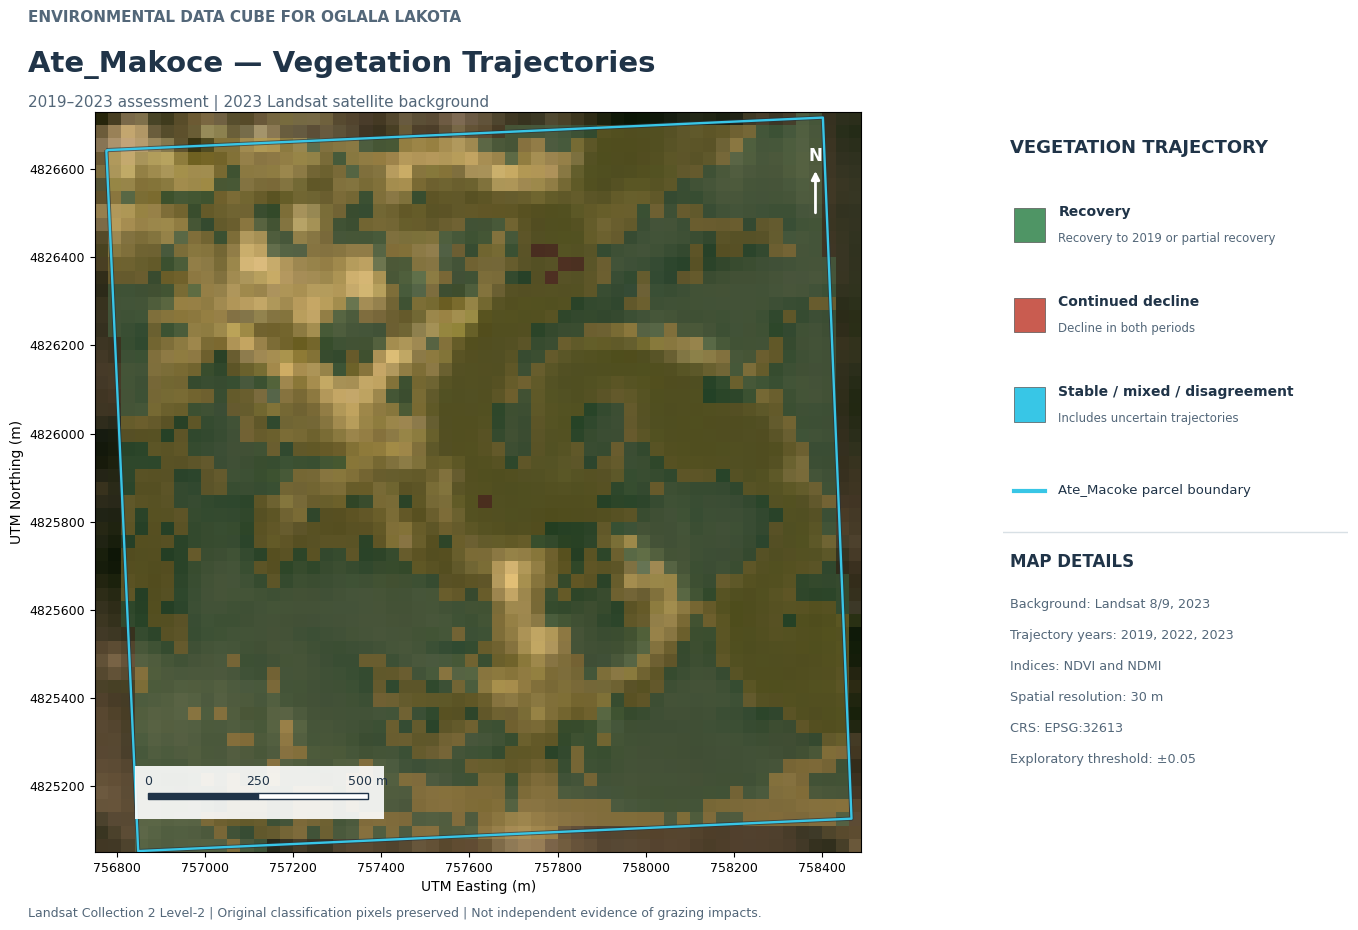


ACCURATE SATELLITE MAP RESTORED
No source rasters or Notebook 09 modified.


In [24]:

# ============================================================
# SA 20 — CELL 13
# RESTORE ACCURATE ATE_MACOKE SATELLITE MAP
#
# No Gaussian smoothing
# No classification interpolation
# No NDVI or NDMI recalculation
# Original files unchanged
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

output_dir = project / "results/SA20_satellite_maps"

raster_path = (
    output_dir
    / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

# ------------------------------------------------------------
# 1. READ ORIGINAL DATA
# ------------------------------------------------------------

if "rgb" not in globals():
    raise RuntimeError(
        "Run Cell 10 first to restore the original RGB image."
    )

with rasterio.open(raster_path) as src:
    classes = src.read(1, masked=True)
    bounds = src.bounds
    crs = src.crs
    shape = (src.height, src.width)

if rgb.shape != (*shape, 3):
    raise ValueError("RGB and classification grids differ.")

if crs.to_epsg() != 32613:
    raise ValueError("Expected EPSG:32613.")

parcel = gpd.read_file(parcel_path).to_crs(crs)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]


# ============================================================
# ATE_MACOKE — UPDATED MAP COLORS
# ============================================================

INK = "#203448"
MUTED = "#536779"

GREEN = "#4F9565"      # Recovery
RED = "#C95C50"        # Continued decline
GRAY = "#E9C85B"       # Stable / mixed / disagreement
YELLOW = "#38C6E6"     # Parcel boundary (cyan blue)

colors = [GREEN, RED, GRAY]

cmap = ListedColormap(colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    cmap.N
)


# ------------------------------------------------------------
# 3. CREATE CLEAN FIGURE
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(15, 10),
    facecolor="white"
)

ax = fig.add_axes([0.08, 0.13, 0.60, 0.74])
panel = fig.add_axes([0.73, 0.16, 0.23, 0.69])

panel.axis("off")
panel.set_xlim(0, 1)
panel.set_ylim(0, 1)

fig.text(
    0.08, 0.96,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    fontsize=11,
    color=MUTED,
    weight="bold"
)

fig.text(
    0.08, 0.91,
    "Ate_Makoce — Vegetation Trajectories",
    fontsize=21,
    color=INK,
    weight="bold"
)

fig.text(
    0.08, 0.875,
    "2019–2023 assessment | 2023 Landsat satellite background",
    fontsize=11,
    color=MUTED
)

# ------------------------------------------------------------
# 4. ORIGINAL SATELLITE IMAGE
# ------------------------------------------------------------

ax.imshow(
    np.clip(rgb, 0, 1),
    extent=extent,
    origin="upper",
    interpolation="nearest",
    zorder=1
)

# ------------------------------------------------------------
# 5. ORIGINAL THREE-CLASS PIXELS
# ------------------------------------------------------------

ax.imshow(
    overlay,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    alpha=0.32,
    interpolation="nearest",
    zorder=2
)

# ------------------------------------------------------------
# 6. PARCEL BOUNDARY
# ------------------------------------------------------------

parcel.boundary.plot(
    ax=ax,
    color="#26313B",
    linewidth=3.0,
    alpha=0.65,
    zorder=3
)

parcel.boundary.plot(
    ax=ax,
    color=YELLOW,
    linewidth=1.7,
    zorder=4
)

ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)
ax.set_aspect("equal")

ax.set_xlabel("UTM Easting (m)", fontsize=10)
ax.set_ylabel("UTM Northing (m)", fontsize=10)

formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)

ax.tick_params(labelsize=9)

# ------------------------------------------------------------
# 7. NORTH ARROW
# ------------------------------------------------------------

ax.annotate(
    "N",
    xy=(0.94, 0.86),
    xytext=(0.94, 0.94),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    color="white",
    arrowprops=dict(
        arrowstyle="<|-",
        color="white",
        lw=2
    )
)

# ------------------------------------------------------------
# 8. SCALE BAR
# ------------------------------------------------------------

x0 = bounds.left + 120
y0 = bounds.bottom + 120

ax.add_patch(
    Rectangle(
        (x0 - 30, y0 - 45),
        565, 120,
        facecolor="white",
        alpha=0.90,
        edgecolor="none",
        zorder=5
    )
)

for i, fill in enumerate([INK, "white"]):
    ax.add_patch(
        Rectangle(
            (x0 + i * 250, y0),
            250, 15,
            facecolor=fill,
            edgecolor=INK,
            linewidth=1,
            zorder=6
        )
    )

for x, label in [
    (x0, "0"),
    (x0 + 250, "250"),
    (x0 + 500, "500 m")
]:
    ax.text(
        x, y0 + 32,
        label,
        fontsize=9,
        ha="center",
        color=INK,
        zorder=7
    )

# ------------------------------------------------------------
# 9. LEGEND AND MAP INFORMATION
# ------------------------------------------------------------

panel.text(
    0.02, 0.97,
    "VEGETATION TRAJECTORY",
    fontsize=13,
    fontweight="bold",
    color=INK
)

legend_items = [
    (GREEN, "Recovery", "Recovery to 2019 or partial recovery"),
    (RED, "Continued decline", "Decline in both periods"),
    (YELLOW, "Stable / mixed / disagreement",
     "Includes uncertain trajectories")
]

for y, (color, label, detail) in zip(
    [0.86, 0.73, 0.60],
    legend_items
):
    panel.add_patch(
        Rectangle(
            (0.03, y - 0.02),
            0.09, 0.05,
            facecolor=color,
            edgecolor="#555555",
            linewidth=0.5
        )
    )

    panel.text(
        0.16, y + 0.018,
        label,
        fontsize=10,
        fontweight="bold",
        color=INK
    )

    panel.text(
        0.16, y - 0.02,
        detail,
        fontsize=8.5,
        color=MUTED
    )

panel.plot(
    [0.03, 0.12],
    [0.48, 0.48],
    color=YELLOW,
    linewidth=3
)

panel.text(
    0.16, 0.48,
    "Ate_Macoke parcel boundary",
    fontsize=9.5,
    color=INK,
    va="center"
)

panel.axhline(
    0.42,
    color="#D8E0E5",
    linewidth=1
)

panel.text(
    0.02, 0.37,
    "MAP DETAILS",
    fontsize=12,
    fontweight="bold",
    color=INK
)

details = [
    "Background: Landsat 8/9, 2023",
    "Trajectory years: 2019, 2022, 2023",
    "Indices: NDVI and NDMI",
    "Spatial resolution: 30 m",
    "CRS: EPSG:32613",
    "Exploratory threshold: ±0.05"
]

for i, detail in enumerate(details):
    panel.text(
        0.02,
        0.31 - i * 0.045,
        detail,
        fontsize=9.2,
        color=MUTED
    )

# ------------------------------------------------------------
# 10. FOOTER
# ------------------------------------------------------------

fig.text(
    0.08, 0.065,
    "Landsat Collection 2 Level-2 | "
    "Original classification pixels preserved | "
    "Not independent evidence of grazing impacts.",
    fontsize=9,
    color=MUTED
)

# ------------------------------------------------------------
# 11. EXPORT WITHOUT OVERWRITING
# ------------------------------------------------------------

base = "Ate_Macoke_Accurate_Satellite_Map"

for extension in ["png", "pdf"]:

    path = output_dir / f"{base}.{extension}"
    version = 2

    while path.exists():
        path = (
            output_dir
            / f"{base}_v{version}.{extension}"
        )
        version += 1

    fig.savefig(
        path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", path)

plt.show()

print("\nACCURATE SATELLITE MAP RESTORED")
print("No source rasters or Notebook 09 modified.")


In [23]:

# ============================================================
# ATE_MACOKE — UPDATED MAP COLORS
# ============================================================

INK = "#203448"
MUTED = "#536779"

GREEN = "#4F9565"      # Recovery
RED = "#C95C50"        # Continued decline
GRAY = "#E9C85B"       # Stable / mixed / disagreement
YELLOW = "#38C6E6"     # Parcel boundary (cyan blue)

colors = [GREEN, RED, GRAY]

cmap = ListedColormap(colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    cmap.N
)


Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_High_Visibility_Vegetation_Map.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_High_Visibility_Vegetation_Map.pdf


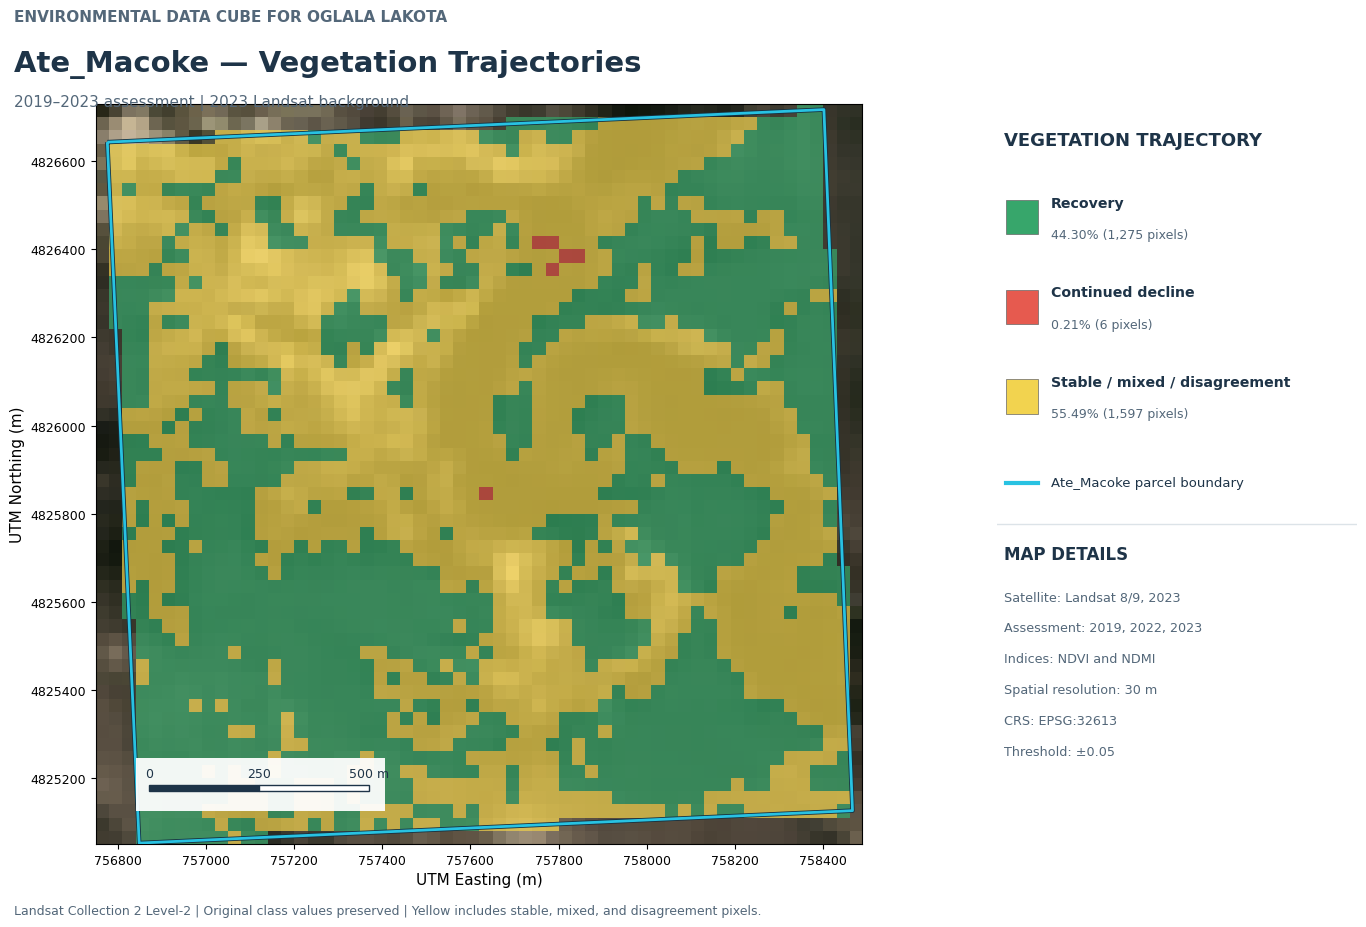


HIGH-VISIBILITY MAP COMPLETE
No original GIS data modified.


In [25]:

# ============================================================
# SA 20 — CELL 14
# ATE_MACOKE — HIGH-VISIBILITY VEGETATION MAP
#
# Preserve original 30 m classification.
# No smoothing or NDVI/NDMI recalculation.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import ScalarFormatter

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

out = project / "results/SA20_satellite_maps"
raster_path = out / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
parcel_path = project / "data/ate_parcel_wanzi.shp"

if "rgb" not in globals():
    raise RuntimeError("Run Cell 10 first to load Landsat RGB.")

with rasterio.open(raster_path) as src:
    classes = src.read(1, masked=True)
    bounds = src.bounds
    crs = src.crs
    shape = (src.height, src.width)

if rgb.shape != (*shape, 3):
    raise ValueError("RGB image and classification grid do not match.")

parcel = gpd.read_file(parcel_path).to_crs(crs)

extent = [
    bounds.left, bounds.right,
    bounds.bottom, bounds.top
]

# ------------------------------------------------------------
# 1. CLASS COLORS AND DISPLAY CONTROLS
# ------------------------------------------------------------

# Higher opacity improves readability.
OVERLAY_OPACITY = 0.72

# Slightly reduce satellite saturation to avoid
# competition with classification colors.
SATELLITE_SATURATION = 0.55

GREEN = "#37A66B"
RED = "#E65A4F"
GOLD = "#F2D34F"
CYAN = "#28C2E2"

INK = "#1E3448"
MUTED = "#536779"

colors = [GREEN, RED, GOLD]

cmap = ListedColormap(colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    cmap.N
)

overlay = np.ma.masked_equal(
    classes.filled(255), 255
)

# ------------------------------------------------------------
# 2. SUBDUE SATELLITE COLORS — DISPLAY ONLY
# ------------------------------------------------------------

rgb_original = np.clip(
    np.asarray(rgb, dtype=float), 0, 1
)

luminance = (
    0.2126 * rgb_original[..., 0]
    + 0.7152 * rgb_original[..., 1]
    + 0.0722 * rgb_original[..., 2]
)

rgb_background = (
    SATELLITE_SATURATION * rgb_original
    + (1 - SATELLITE_SATURATION)
    * luminance[..., None]
)

# Slightly brighten the background
rgb_background = np.clip(
    rgb_background * 1.08, 0, 1
)

# ------------------------------------------------------------
# 3. CALCULATE CLASS PERCENTAGES
# ------------------------------------------------------------

valid = ~np.ma.getmaskarray(classes)
values = classes.data[valid]

counts = {
    i: int(np.sum(values == i))
    for i in [1, 2, 3]
}

total = len(values)

percentages = {
    i: 100 * counts[i] / total
    for i in [1, 2, 3]
}

# ------------------------------------------------------------
# 4. CREATE MAP LAYOUT
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(15, 10),
    facecolor="white"
)

ax = fig.add_axes([0.075, 0.13, 0.62, 0.74])
panel = fig.add_axes([0.73, 0.16, 0.24, 0.69])

panel.axis("off")
panel.set_xlim(0, 1)
panel.set_ylim(0, 1)

fig.text(
    0.075, 0.965,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    fontsize=11,
    weight="bold",
    color=MUTED,
    va="top"
)

fig.text(
    0.075, 0.925,
    "Ate_Macoke — Vegetation Trajectories",
    fontsize=21,
    weight="bold",
    color=INK,
    va="top"
)

fig.text(
    0.075, 0.88,
    "2019–2023 assessment | 2023 Landsat background",
    fontsize=11,
    color=MUTED,
    va="top"
)

# ------------------------------------------------------------
# 5. SATELLITE + CLASSIFICATION
# ------------------------------------------------------------

ax.imshow(
    rgb_background,
    extent=extent,
    origin="upper",
    interpolation="nearest",
    zorder=1
)

ax.imshow(
    overlay,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    alpha=OVERLAY_OPACITY,
    interpolation="nearest",
    zorder=2
)

parcel.boundary.plot(
    ax=ax,
    color="#153040",
    linewidth=3.2,
    zorder=3
)

parcel.boundary.plot(
    ax=ax,
    color=CYAN,
    linewidth=2.0,
    zorder=4
)

ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)
ax.set_aspect("equal")

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")

fmt = ScalarFormatter(useOffset=False)
fmt.set_scientific(False)

ax.xaxis.set_major_formatter(fmt)
ax.yaxis.set_major_formatter(fmt)

ax.tick_params(labelsize=9)

# ------------------------------------------------------------
# 6. SCALE BAR
# ------------------------------------------------------------

if crs.to_epsg() != 32613:
    raise ValueError("Expected EPSG:32613 for meter scale.")

x0 = bounds.left + 120
y0 = bounds.bottom + 120

ax.add_patch(
    Rectangle(
        (x0 - 30, y0 - 45),
        565, 120,
        facecolor="white",
        edgecolor="none",
        alpha=0.94,
        zorder=5
    )
)

for i, fill in enumerate([INK, "white"]):
    ax.add_patch(
        Rectangle(
            (x0 + i * 250, y0),
            250, 15,
            facecolor=fill,
            edgecolor=INK,
            linewidth=1,
            zorder=6
        )
    )

for x, label in [
    (x0, "0"),
    (x0 + 250, "250"),
    (x0 + 500, "500 m")
]:
    ax.text(
        x, y0 + 33,
        label,
        ha="center",
        fontsize=9,
        color=INK,
        zorder=7
    )

# ------------------------------------------------------------
# 7. LEGEND WITH ACTUAL CLASS PERCENTAGES
# ------------------------------------------------------------

panel.text(
    0.02, 0.97,
    "VEGETATION TRAJECTORY",
    fontsize=13,
    fontweight="bold",
    color=INK
)

legend_data = [
    (1, GREEN, "Recovery"),
    (2, RED, "Continued decline"),
    (3, GOLD, "Stable / mixed / disagreement")
]

for y, (class_id, color, label) in zip(
    [0.86, 0.73, 0.60],
    legend_data
):

    panel.add_patch(
        Rectangle(
            (0.025, y - 0.02),
            0.09, 0.05,
            facecolor=color,
            edgecolor="#666666",
            linewidth=0.5
        )
    )

    panel.text(
        0.15, y + 0.02,
        label,
        fontsize=10.2,
        fontweight="bold",
        color=INK
    )

    panel.text(
        0.15, y - 0.025,
        f"{percentages[class_id]:.2f}% "
        f"({counts[class_id]:,} pixels)",
        fontsize=9,
        color=MUTED
    )

panel.plot(
    [0.025, 0.115],
    [0.48, 0.48],
    color=CYAN,
    linewidth=3
)

panel.text(
    0.15, 0.48,
    "Ate_Macoke parcel boundary",
    fontsize=9.5,
    color=INK,
    va="center"
)

panel.axhline(
    0.42,
    color="#DCE3E8",
    linewidth=1
)

panel.text(
    0.02, 0.37,
    "MAP DETAILS",
    fontsize=12,
    fontweight="bold",
    color=INK
)

details = [
    "Satellite: Landsat 8/9, 2023",
    "Assessment: 2019, 2022, 2023",
    "Indices: NDVI and NDMI",
    "Spatial resolution: 30 m",
    "CRS: EPSG:32613",
    "Threshold: ±0.05"
]

for i, detail in enumerate(details):
    panel.text(
        0.02,
        0.31 - i * 0.045,
        detail,
        fontsize=9.2,
        color=MUTED
    )

# ------------------------------------------------------------
# 8. EXPORT
# ------------------------------------------------------------

fig.text(
    0.075, 0.06,
    "Landsat Collection 2 Level-2 | "
    "Original class values preserved | "
    "Yellow includes stable, mixed, and disagreement pixels.",
    fontsize=9,
    color=MUTED
)

base = "Ate_Macoke_High_Visibility_Vegetation_Map"

for extension in ["png", "pdf"]:

    path = out / f"{base}.{extension}"
    version = 2

    while path.exists():
        path = out / f"{base}_v{version}.{extension}"
        version += 1

    fig.savefig(
        path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", path)

plt.show()

print("\nHIGH-VISIBILITY MAP COMPLETE")
print("No original GIS data modified.")


ATE_MACOKE — THREE-CLASS SUMMARY
Recovery: 1,275 pixels (44.30%)
Continued decline: 6 pixels (0.21%)
Stable / mixed / disagreement: 1,597 pixels (55.49%)
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Satellite_Vegetation_Map_58pct_Opacity.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Satellite_Vegetation_Map_58pct_Opacity.pdf


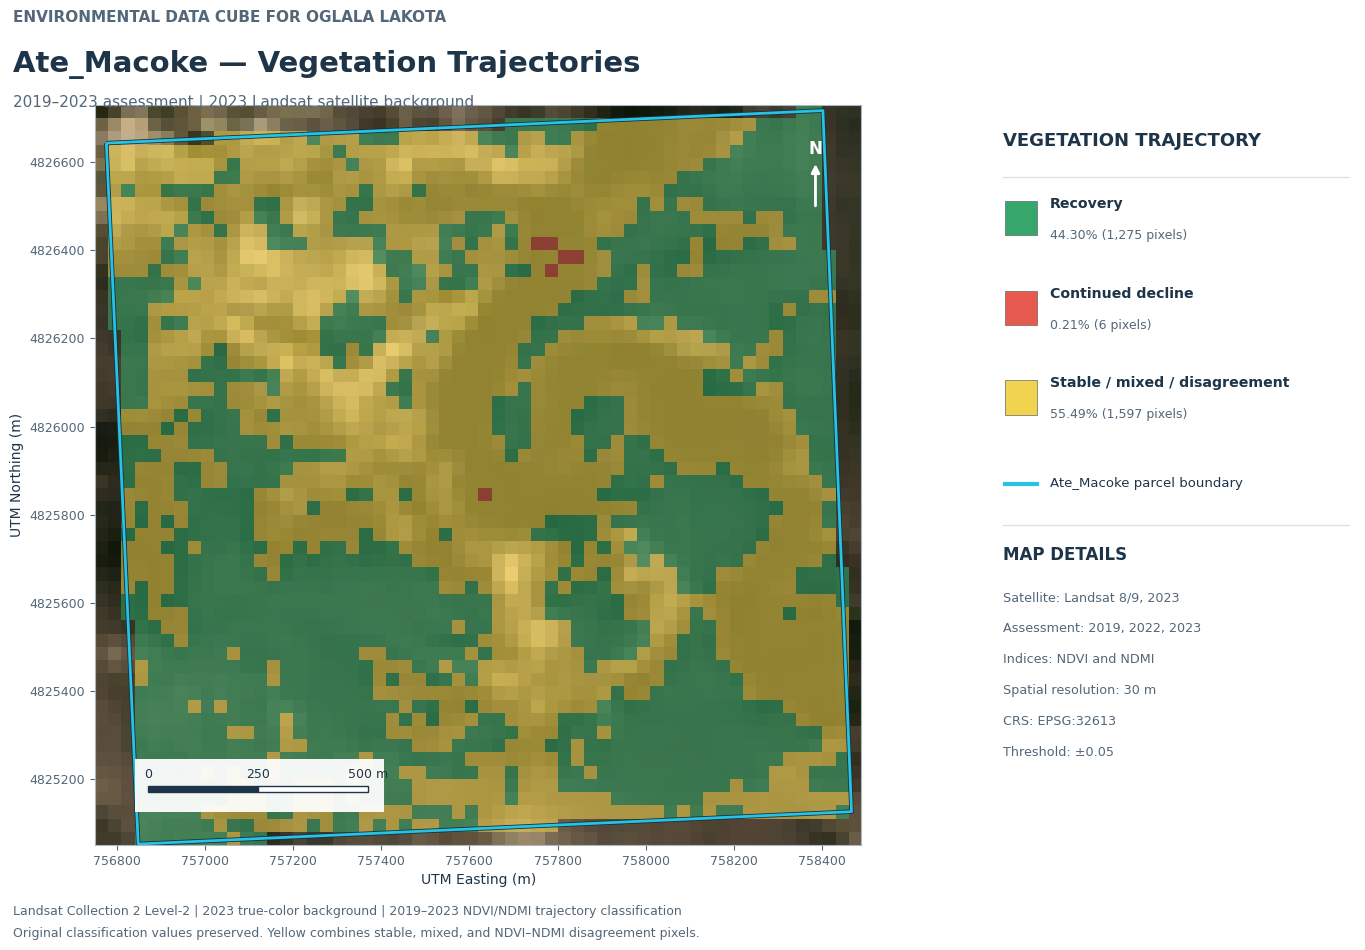


SA 20 — UPDATED SATELLITE MAP COMPLETE
Vegetation overlay opacity: 58%
Satellite image visibility: increased
Original classification pixels: unchanged
Original Notebook 09: unchanged


In [26]:

# ============================================================
# SA 20 — CELL 14 (UPDATED)
# ATE_MACOKE — SATELLITE VEGETATION TRAJECTORY MAP
# Environmental Data Cube for Oglala Lakota
#
# Background: Actual 2023 Landsat satellite image
# Overlay: 2019–2023 three-class vegetation trajectories
#
# Classification opacity: 58%
# Original GIS data and Notebook 09 remain unchanged.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import ScalarFormatter

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

output_dir = project / "results/SA20_satellite_maps"
output_dir.mkdir(parents=True, exist_ok=True)

raster_path = (
    output_dir
    / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

# ------------------------------------------------------------
# 2. LOAD EXISTING DATA
# ------------------------------------------------------------

if "rgb" not in globals():
    raise RuntimeError(
        "Run Cell 10 first to load the 2023 Landsat RGB image."
    )

with rasterio.open(raster_path) as src:
    classes = src.read(1, masked=True)
    bounds = src.bounds
    crs = src.crs
    shape = (src.height, src.width)

if rgb.shape != (*shape, 3):
    raise ValueError(
        "Satellite image and vegetation raster "
        "do not have matching dimensions."
    )

if crs.to_epsg() != 32613:
    raise ValueError(
        "Expected EPSG:32613 for this map."
    )

parcel = gpd.read_file(parcel_path)

if parcel.crs is None:
    raise ValueError("Parcel shapefile has no CRS.")

parcel = parcel.to_crs(crs)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

# ------------------------------------------------------------
# 3. MAP COLORS AND TRANSPARENCY
# ------------------------------------------------------------

# 58% vegetation overlay.
# The remaining 42% allows satellite imagery to show through.
OVERLAY_OPACITY = 0.58

# Keep the satellite imagery slightly subdued,
# but retain its original pixel geometry.
SATELLITE_SATURATION = 0.75

GREEN = "#37A66B"   # Recovery
RED = "#E65A4F"     # Continued decline
GOLD = "#F2D34F"    # Stable / mixed / disagreement
CYAN = "#28C2E2"    # Ate_Macoke parcel boundary

INK = "#1E3448"
MUTED = "#536779"
DIVIDER = "#DCE3E8"

colors = [GREEN, RED, GOLD]

cmap = ListedColormap(colors)
cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    cmap.N
)

# Preserve NoData as transparent.
overlay = np.ma.masked_equal(
    classes.filled(255),
    255
)

# ------------------------------------------------------------
# 4. PREPARE SATELLITE BACKGROUND
# ------------------------------------------------------------

rgb_original = np.clip(
    np.asarray(rgb, dtype=np.float32),
    0,
    1
)

# Adjust saturation for display only.
# No spatial smoothing or resampling.
luminance = (
    0.2126 * rgb_original[..., 0]
    + 0.7152 * rgb_original[..., 1]
    + 0.0722 * rgb_original[..., 2]
)

rgb_background = (
    SATELLITE_SATURATION * rgb_original
    + (1 - SATELLITE_SATURATION)
    * luminance[..., None]
)

rgb_background = np.clip(
    rgb_background * 1.05,
    0,
    1
)

# ------------------------------------------------------------
# 5. CALCULATE CLASS PERCENTAGES
# ------------------------------------------------------------

valid = ~np.ma.getmaskarray(classes)
values = classes.data[valid]

expected_classes = {1, 2, 3}
found_classes = set(np.unique(values).tolist())

if not found_classes.issubset(expected_classes):
    raise ValueError(
        f"Unexpected classification values: "
        f"{found_classes - expected_classes}"
    )

counts = {
    class_id: int(np.sum(values == class_id))
    for class_id in [1, 2, 3]
}

total_pixels = len(values)

if total_pixels == 0:
    raise ValueError("No valid classified pixels found.")

percentages = {
    class_id: (
        100 * counts[class_id] / total_pixels
    )
    for class_id in [1, 2, 3]
}

print("ATE_MACOKE — THREE-CLASS SUMMARY")
print("=" * 50)

for class_id, label in [
    (1, "Recovery"),
    (2, "Continued decline"),
    (3, "Stable / mixed / disagreement")
]:
    print(
        f"{label}: "
        f"{counts[class_id]:,} pixels "
        f"({percentages[class_id]:.2f}%)"
    )

# ------------------------------------------------------------
# 6. CREATE PROFESSIONAL MAP LAYOUT
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig = plt.figure(
    figsize=(15, 10),
    facecolor="white"
)

# Main map
ax = fig.add_axes([
    0.075, 0.13,
    0.62, 0.74
])

# Information panel
panel = fig.add_axes([
    0.73, 0.16,
    0.24, 0.69
])

panel.axis("off")
panel.set_xlim(0, 1)
panel.set_ylim(0, 1)

# ------------------------------------------------------------
# 7. TITLE AND SUBTITLE
# ------------------------------------------------------------

fig.text(
    0.075,
    0.965,
    "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
    fontsize=11,
    weight="bold",
    color=MUTED,
    va="top"
)

fig.text(
    0.075,
    0.925,
    "Ate_Macoke — Vegetation Trajectories",
    fontsize=21,
    weight="bold",
    color=INK,
    va="top"
)

fig.text(
    0.075,
    0.88,
    "2019–2023 assessment | 2023 Landsat satellite background",
    fontsize=11,
    color=MUTED,
    va="top"
)

# ------------------------------------------------------------
# 8. DRAW ACTUAL LANDSAT SATELLITE IMAGE
# ------------------------------------------------------------

ax.imshow(
    rgb_background,
    extent=extent,
    origin="upper",
    interpolation="nearest",
    zorder=1
)

# ------------------------------------------------------------
# 9. DRAW TRANSPARENT VEGETATION CLASSIFICATION
# ------------------------------------------------------------

ax.imshow(
    overlay,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    alpha=OVERLAY_OPACITY,
    interpolation="nearest",
    zorder=2
)

# ------------------------------------------------------------
# 10. DRAW PARCEL BOUNDARY
# ------------------------------------------------------------

# Dark outline for contrast
parcel.boundary.plot(
    ax=ax,
    color="#153040",
    linewidth=3.2,
    zorder=3
)

# Cyan-blue parcel boundary
parcel.boundary.plot(
    ax=ax,
    color=CYAN,
    linewidth=2.0,
    zorder=4
)

ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)
ax.set_aspect("equal")

ax.set_xlabel(
    "UTM Easting (m)",
    fontsize=10,
    color=INK
)

ax.set_ylabel(
    "UTM Northing (m)",
    fontsize=10,
    color=INK
)

formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)

ax.tick_params(
    axis="both",
    labelsize=9,
    colors=MUTED
)

for spine in ax.spines.values():
    spine.set_color("#AAB7C2")
    spine.set_linewidth(0.8)

# ------------------------------------------------------------
# 11. NORTH ARROW
# ------------------------------------------------------------

ax.annotate(
    "N",
    xy=(0.94, 0.86),
    xytext=(0.94, 0.94),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    color="white",
    arrowprops=dict(
        arrowstyle="<|-",
        color="white",
        lw=2
    )
)

# ------------------------------------------------------------
# 12. 500-METER SCALE BAR
# ------------------------------------------------------------

x0 = bounds.left + 120
y0 = bounds.bottom + 120

# White background behind scale
ax.add_patch(
    Rectangle(
        (x0 - 30, y0 - 45),
        565,
        120,
        facecolor="white",
        edgecolor="none",
        alpha=0.94,
        zorder=5
    )
)

# Alternating scale segments
for i, fill in enumerate([INK, "white"]):

    ax.add_patch(
        Rectangle(
            (x0 + i * 250, y0),
            250,
            15,
            facecolor=fill,
            edgecolor=INK,
            linewidth=1,
            zorder=6
        )
    )

# Scale labels
for x, label in [
    (x0, "0"),
    (x0 + 250, "250"),
    (x0 + 500, "500 m")
]:

    ax.text(
        x,
        y0 + 33,
        label,
        ha="center",
        fontsize=9,
        color=INK,
        zorder=7
    )

# ------------------------------------------------------------
# 13. VEGETATION LEGEND
# ------------------------------------------------------------

panel.text(
    0.02,
    0.97,
    "VEGETATION TRAJECTORY",
    fontsize=13,
    fontweight="bold",
    color=INK
)

panel.plot(
    [0.02, 0.98],
    [0.925, 0.925],
    color=DIVIDER,
    linewidth=1
)

legend_data = [
    (1, GREEN, "Recovery"),
    (2, RED, "Continued decline"),
    (3, GOLD, "Stable / mixed / disagreement")
]

legend_positions = [
    0.86,
    0.73,
    0.60
]

for y, (class_id, color, label) in zip(
    legend_positions,
    legend_data
):

    # Color square
    panel.add_patch(
        Rectangle(
            (0.025, y - 0.02),
            0.09,
            0.05,
            facecolor=color,
            edgecolor="#666666",
            linewidth=0.5
        )
    )

    # Classification name
    panel.text(
        0.15,
        y + 0.02,
        label,
        fontsize=10.2,
        fontweight="bold",
        color=INK
    )

    # Percentage and pixel count
    panel.text(
        0.15,
        y - 0.025,
        (
            f"{percentages[class_id]:.2f}% "
            f"({counts[class_id]:,} pixels)"
        ),
        fontsize=9,
        color=MUTED
    )

# Parcel boundary legend
panel.plot(
    [0.025, 0.115],
    [0.48, 0.48],
    color=CYAN,
    linewidth=3
)

panel.text(
    0.15,
    0.48,
    "Ate_Macoke parcel boundary",
    fontsize=9.5,
    color=INK,
    va="center"
)

# ------------------------------------------------------------
# 14. MAP DETAILS
# ------------------------------------------------------------

panel.plot(
    [0.02, 0.98],
    [0.42, 0.42],
    color=DIVIDER,
    linewidth=1
)

panel.text(
    0.02,
    0.37,
    "MAP DETAILS",
    fontsize=12,
    fontweight="bold",
    color=INK
)

details = [
    "Satellite: Landsat 8/9, 2023",
    "Assessment: 2019, 2022, 2023",
    "Indices: NDVI and NDMI",
    "Spatial resolution: 30 m",
    "CRS: EPSG:32613",
    "Threshold: ±0.05"
]

for i, detail in enumerate(details):

    panel.text(
        0.02,
        0.31 - i * 0.045,
        detail,
        fontsize=9.2,
        color=MUTED
    )

# ------------------------------------------------------------
# 15. SCIENTIFIC FOOTER
# ------------------------------------------------------------

fig.text(
    0.075,
    0.060,
    "Landsat Collection 2 Level-2 | "
    "2023 true-color background | "
    "2019–2023 NDVI/NDMI trajectory classification",
    fontsize=9,
    color=MUTED
)

fig.text(
    0.075,
    0.038,
    "Original classification values preserved. "
    "Yellow combines stable, mixed, and "
    "NDVI–NDMI disagreement pixels.",
    fontsize=9,
    color=MUTED
)

# ------------------------------------------------------------
# 16. EXPORT 400-DPI PNG AND PDF
# ------------------------------------------------------------

base_name = (
    "Ate_Macoke_Satellite_"
    "Vegetation_Map_58pct_Opacity"
)

for extension in ["png", "pdf"]:

    export_path = (
        output_dir / f"{base_name}.{extension}"
    )

    version = 2

    # Never overwrite an existing figure.
    while export_path.exists():

        export_path = (
            output_dir
            / f"{base_name}_v{version}.{extension}"
        )

        version += 1

    fig.savefig(
        export_path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
        pad_inches=0.15
    )

    print("Saved:", export_path)

plt.show()

print("\n" + "=" * 60)
print("SA 20 — UPDATED SATELLITE MAP COMPLETE")
print("=" * 60)
print("Vegetation overlay opacity: 58%")
print("Satellite image visibility: increased")
print("Original classification pixels: unchanged")
print("Original Notebook 09: unchanged")


Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_True_Color_Composite_Comparison.png
Saved: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_True_Color_Composite_Comparison.pdf


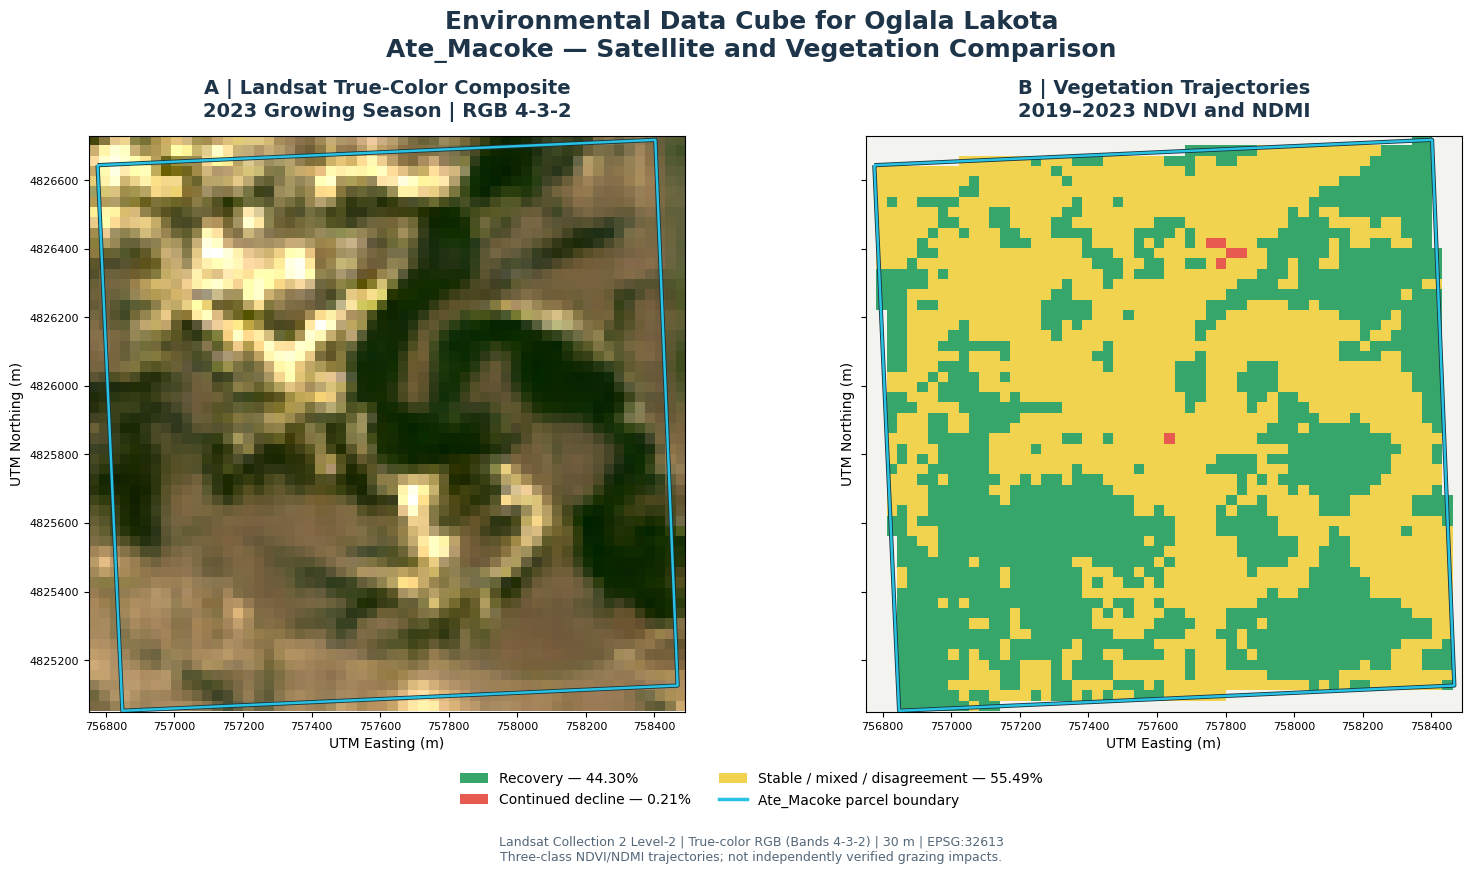


TRUE-COLOR COMPOSITE COMPLETE
Original classification data unchanged.


In [27]:

# ============================================================
# SA 20 — CELL 16
# TRUE-COLOR LANDSAT COMPOSITE + VEGETATION TRAJECTORIES
# Environmental Data Cube for Oglala Lakota
#
# LEFT: Landsat 8/9 true-color RGB composite (4-3-2)
# RIGHT: Existing three-class NDVI/NDMI trajectories
#
# No smoothing or classification changes.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter

# ------------------------------------------------------------
# 1. PATHS AND DATA
# ------------------------------------------------------------

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

out = project / "results/SA20_satellite_maps"
out.mkdir(parents=True, exist_ok=True)

raster_path = (
    out / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

parcel_path = project / "data/ate_parcel_wanzi.shp"

if "rgb" not in globals():
    raise RuntimeError(
        "Run Cell 10 first to load Landsat RGB bands."
    )

with rasterio.open(raster_path) as src:
    classes = src.read(1, masked=True)
    bounds = src.bounds
    crs = src.crs
    shape = (src.height, src.width)

if rgb.shape != (*shape, 3):
    raise ValueError(
        "RGB and classification raster dimensions do not match."
    )

parcel = gpd.read_file(parcel_path).to_crs(crs)

extent = [
    bounds.left, bounds.right,
    bounds.bottom, bounds.top
]

# ------------------------------------------------------------
# 2. TRUE-COLOR DISPLAY ENHANCEMENT
# ------------------------------------------------------------

# Cell 10's rgb is already ordered Red-Green-Blue,
# with Landsat C2 L2 reflectance scaling applied.
#
# The following stretch improves visual contrast only.
# It does not alter the source band data.

rgb_input = np.clip(
    np.asarray(rgb, dtype=np.float32),
    0, 1
)

# Use a shared percentile stretch across all RGB bands.
# Shared stretching preserves relative channel balance.
valid_rgb = (
    np.all(np.isfinite(rgb_input), axis=2)
    & np.any(rgb_input > 0, axis=2)
)

if not np.any(valid_rgb):
    raise ValueError("No valid RGB pixels available.")

low, high = np.percentile(
    rgb_input[valid_rgb],
    [2, 98]
)

if high <= low:
    raise ValueError("RGB image has insufficient contrast.")

rgb_truecolor = np.clip(
    (rgb_input - low) / (high - low),
    0, 1
)

# Mild gamma adjustment for natural display.
GAMMA = 1.10

rgb_truecolor = np.power(
    rgb_truecolor,
    1.0 / GAMMA
)

# ------------------------------------------------------------
# 3. THREE-CLASS COLORS
# ------------------------------------------------------------

GREEN = "#37A66B"
RED = "#E65A4F"
GOLD = "#F2D34F"
CYAN = "#28C2E2"

INK = "#1E3448"
MUTED = "#536779"

cmap = ListedColormap([
    GREEN,
    RED,
    GOLD
])

cmap.set_bad((0, 0, 0, 0))

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    cmap.N
)

overlay = np.ma.masked_equal(
    classes.filled(255),
    255
)

# ------------------------------------------------------------
# 4. CLASS STATISTICS
# ------------------------------------------------------------

values = classes.compressed()

counts = {
    i: int(np.sum(values == i))
    for i in [1, 2, 3]
}

total = len(values)

percentages = {
    i: 100 * counts[i] / total
    for i in [1, 2, 3]
}

# ------------------------------------------------------------
# 5. SIDE-BY-SIDE FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 9),
    sharex=True,
    sharey=True
)

fig.patch.set_facecolor("white")

# LEFT: TRUE-COLOR LANDSAT
axes[0].imshow(
    rgb_truecolor,
    extent=extent,
    origin="upper",
    interpolation="nearest"
)

axes[0].set_title(
    "A | Landsat True-Color Composite\n"
    "2023 Growing Season | RGB 4-3-2",
    fontsize=14,
    fontweight="bold",
    color=INK,
    pad=14
)

# RIGHT: VEGETATION CLASSIFICATION
axes[1].set_facecolor("#F3F3EF")

axes[1].imshow(
    overlay,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

axes[1].set_title(
    "B | Vegetation Trajectories\n"
    "2019–2023 NDVI and NDMI",
    fontsize=14,
    fontweight="bold",
    color=INK,
    pad=14
)

# ------------------------------------------------------------
# 6. PARCEL BOUNDARY AND MAP AXES
# ------------------------------------------------------------

for ax in axes:

    parcel.boundary.plot(
        ax=ax,
        color="#18313D",
        linewidth=3,
        zorder=4
    )

    parcel.boundary.plot(
        ax=ax,
        color=CYAN,
        linewidth=1.8,
        zorder=5
    )

    ax.set_xlim(bounds.left, bounds.right)
    ax.set_ylim(bounds.bottom, bounds.top)
    ax.set_aspect("equal")

    ax.set_xlabel(
        "UTM Easting (m)",
        fontsize=10
    )

    ax.set_ylabel(
        "UTM Northing (m)",
        fontsize=10
    )

    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)

    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)

    ax.tick_params(labelsize=8)

# ------------------------------------------------------------
# 7. LEGEND
# ------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor=GREEN,
        label=f"Recovery — {percentages[1]:.2f}%"
    ),
    Patch(
        facecolor=RED,
        label=f"Continued decline — {percentages[2]:.2f}%"
    ),
    Patch(
        facecolor=GOLD,
        label=(
            "Stable / mixed / disagreement "
            f"— {percentages[3]:.2f}%"
        )
    ),
    Line2D(
        [0], [0],
        color=CYAN,
        linewidth=2.5,
        label="Ate_Macoke parcel boundary"
    )
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.07),
    ncol=2,
    frameon=False,
    fontsize=10
)

# ------------------------------------------------------------
# 8. TITLE AND FOOTNOTE
# ------------------------------------------------------------

fig.suptitle(
    "Environmental Data Cube for Oglala Lakota\n"
    "Ate_Macoke — Satellite and Vegetation Comparison",
    fontsize=18,
    fontweight="bold",
    color=INK,
    y=0.97
)

fig.text(
    0.5, 0.025,
    "Landsat Collection 2 Level-2 | "
    "True-color RGB (Bands 4-3-2) | "
    "30 m | EPSG:32613\n"
    "Three-class NDVI/NDMI trajectories; "
    "not independently verified grazing impacts.",
    ha="center",
    fontsize=9,
    color=MUTED
)

plt.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.83,
    bottom=0.19,
    wspace=0.20
)

# ------------------------------------------------------------
# 9. EXPORT
# ------------------------------------------------------------

base = "Ate_Macoke_True_Color_Composite_Comparison"

for extension in ["png", "pdf"]:

    path = out / f"{base}.{extension}"
    version = 2

    while path.exists():
        path = out / f"{base}_v{version}.{extension}"
        version += 1

    fig.savefig(
        path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", path)

plt.show()

print("\nTRUE-COLOR COMPOSITE COMPLETE")
print("Original classification data unchanged.")


In [30]:
print("RGB available:", "rgb" in globals())

if "rgb" in globals():
    print("RGB shape:", rgb.shape)
    print("RGB range:", np.nanmin(rgb), np.nanmax(rgb))

RGB available: True
RGB shape: (56, 58, 3)
RGB range: 0.0 0.8803666


In [31]:

# ============================================================
# SAVE 2023 LANDSAT TRUE-COLOR RGB
# For Notebook 13 — Dissertation Map Atlas
# ============================================================

from pathlib import Path
import numpy as np
import rasterio

project = (
    Path.home()
    / "Documents/ElishaWakinyanZi-WORK"
    / "datacube_2026/ate_makoce_agcube"
)

out = project / "results/SA20_satellite_maps"

reference_raster = (
    out / "Ate_Macoke_Three_Class_Vegetation_Trajectories.tif"
)

rgb_path = (
    out / "Ate_Macoke_Landsat_2023_TrueColor_RGB.tif"
)

with rasterio.open(reference_raster) as ref:

    if rgb.shape != (ref.height, ref.width, 3):
        raise ValueError("RGB and raster dimensions do not match.")

    profile = ref.profile.copy()

profile.update(
    driver="GTiff",
    count=3,
    dtype="float32",
    nodata=None,
    compress="deflate",
    photometric="RGB"
)

# Protect an existing export from accidental replacement.
if rgb_path.exists():
    raise FileExistsError(
        f"File already exists: {rgb_path}"
    )

with rasterio.open(rgb_path, "w", **profile):

    pass

# Write RGB channels
with rasterio.open(rgb_path, "r+") as dst:

    for i in range(3):
        dst.write(
            np.asarray(rgb[:, :, i], dtype="float32"),
            i + 1
        )

    dst.set_band_description(1, "Red — Landsat B4")
    dst.set_band_description(2, "Green — Landsat B3")
    dst.set_band_description(3, "Blue — Landsat B2")

    dst.update_tags(
        title="Ate_Macoke 2023 Landsat True-Color",
        source_scene=chosen_scene.id,
        acquisition=str(
            chosen_scene.properties.get("datetime")
        ),
        description="Display-stretched RGB composite"
    )

print("LANDSAT RGB SAVED SUCCESSFULLY")
print("File:", rgb_path)
print("Dimensions:", rgb.shape)
print("Original data cube unchanged.")


LANDSAT RGB SAVED SUCCESSFULLY
File: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_Landsat_2023_TrueColor_RGB.tif
Dimensions: (56, 58, 3)
Original data cube unchanged.
